# Supplementary code and figure generation

**Richardson, Uchikawa, and Zeebe (2026)**  
*Determination of carbonic acid dissociation constants in artificial seawater of non-standard major-ion composition*

This notebook contains the data loading, calculations, statistical analyses, and figure-generation code supporting the manuscript.

## Reproducibility instructions

1. Install the Python packages listed in the imports/configuration cell.
2. Place the two input Excel workbooks in the notebook directory:
   - `01_K1*K2*_Data.xlsx`
3. If the files are stored elsewhere, update `DATA_WORKBOOK` in the configuration cell.
4. Run the notebook from top to bottom. Figures are written to the `figures/` directory.

The plotting styles, figure dimensions, data transformations, regression procedures, confidence-interval calculations, and carbonate-system calculations have been retained. The edits focus on code organization, reproducibility, redundant imports, file-path configuration, and execution robustness.


In [36]:
# 1. Imports and configuration
#
# Tested workflow dependencies:
# pandas, numpy, matplotlib, scipy, scikit-learn, openpyxl, PyCO2SYS
#
# Place the two input workbooks in the same directory as this notebook, or
# update the paths below before running the analysis.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PyCO2SYS as pyco2

from matplotlib.lines import Line2D
from scipy import stats
from scipy.stats import linregress, probplot
from sklearn.linear_model import LinearRegression


DATA_WORKBOOK = Path("01_K1*K2*_Data.xlsx")
FIGURE_OUTPUT_DIR = Path("figures")
FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [37]:
# 2. Load experimental and model data
#
# Input workbook: DATA_WORKBOOK
# Required sheets: Model_Data, Raw_Titration_eg, Experimental_Data,
# MARCHEMSPEC_Full_Range, and Compare_std_pK.

if not DATA_WORKBOOK.is_file():
    raise FileNotFoundError(
        f"Could not find the data workbook: {DATA_WORKBOOK.resolve()}. "
        "Update DATA_WORKBOOK in the imports/configuration cell."
    )

stdpk = pd.read_excel(DATA_WORKBOOK, sheet_name="Model_Data")
de = pd.read_excel(DATA_WORKBOOK, sheet_name="Raw_Titration_eg")
dat = pd.read_excel(DATA_WORKBOOK, sheet_name="Experimental_Data")
fullrange = pd.read_excel(DATA_WORKBOOK, sheet_name="MARCHEMSPEC_Full_Range")
comparestdpk = pd.read_excel(DATA_WORKBOOK, sheet_name="Compare_std_pK")


In [38]:
# Figure 1
#
# Figure 1 was prepared separately in Microsoft PowerPoint.


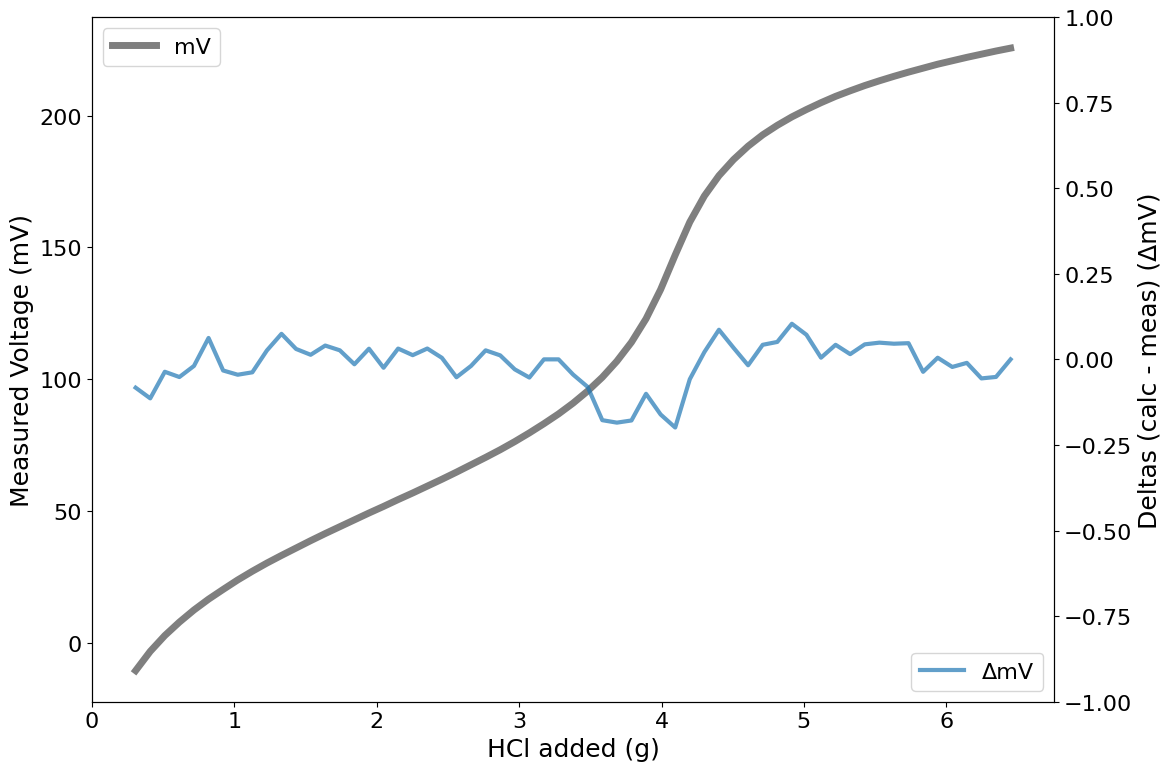

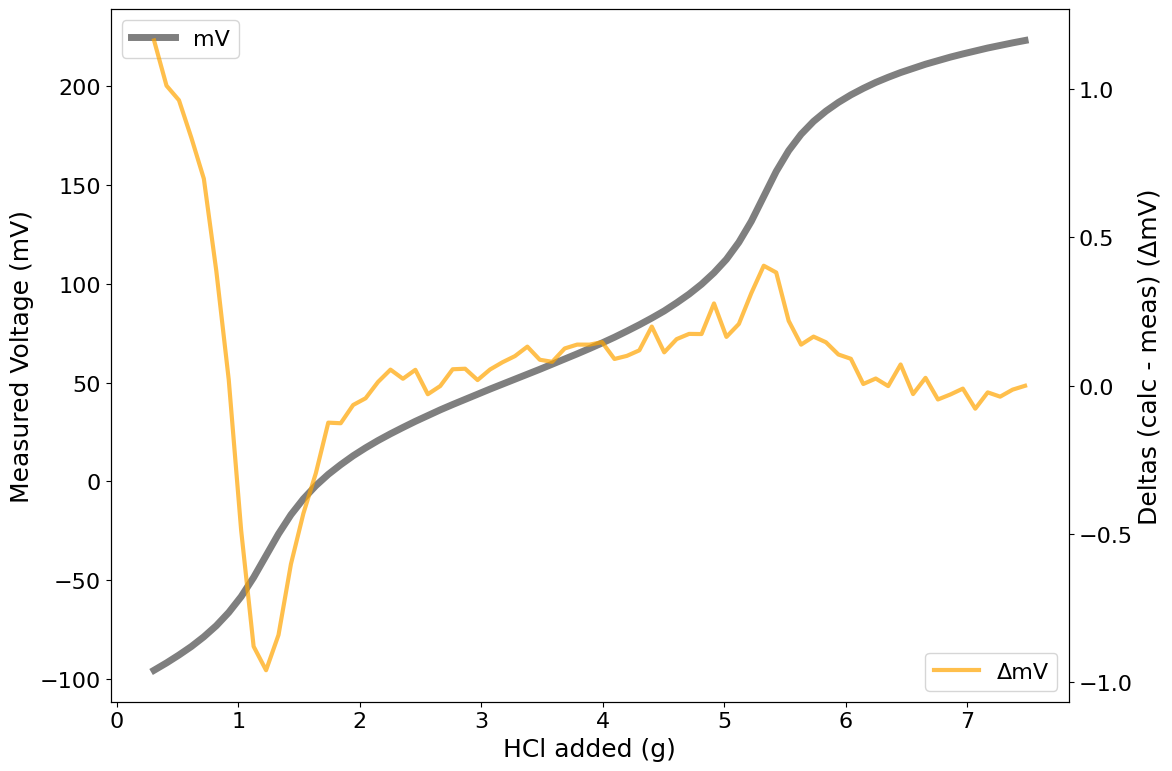

In [39]:
# Figure 2
#
# Configure plot-wide styling, then generate the experimental measurement
# and calibration figure.

plt.rcParams['font.size'] = 16
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 16

fig, ax1 = plt.subplots(figsize=(12,8))

# Define line styles for each sample
line_styles = {1: '-', 2: '-'}

samples_to_plot = [1]

# Primary axis (emf)
for sample in samples_to_plot:
    sample_data = de[de['Sample'] == sample]
    ax1.plot(
        sample_data['m( 1)'],
        sample_data['emf( 1)'],
        color='black',
        alpha=0.5,
        linewidth=5,
        linestyle=line_styles[sample],
        label=f'mV'
    )

ax1.set_xlabel('HCl added (g)')
ax1.set_ylabel('Measured Voltage (mV)')
ax1.legend(loc='upper left')

# Secondary axis (Deltas)
ax2 = ax1.twinx()
for sample in samples_to_plot:
    sample_data = de[de['Sample'] == sample]
    ax2.plot(
        sample_data['m( 1)'],
        sample_data['Deltas( 1)'],
        linestyle='-',
        alpha=0.7,
        linewidth=3,
        label=f'ΔmV'

    )

ax2.set_ylabel('Deltas (calc - meas) (ΔmV)')
ax2.legend(loc='lower right')
ax2.set_ylim(-1, 1)

plt.tight_layout()
fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_2.png', dpi=600, bbox_inches='tight')
plt.show()

##################sample 3,4

fig, ax1 = plt.subplots(figsize=(12,8))

# Define line styles for each sample
line_styles = {3: '-', 4: '-'}

samples_to_plot = [3]

# Primary axis (emf)
for sample in samples_to_plot:
    sample_data = de[de['Sample'] == sample]
    ax1.plot(
        sample_data['m( 1)'],
        sample_data['emf( 1)'],
        color='black',
        alpha=0.5,
        linewidth=5,
        linestyle=line_styles[sample],
        label=f'mV'
    )

ax1.set_xlabel('HCl added (g)')
ax1.set_ylabel('Measured Voltage (mV)')
ax1.legend(loc='upper left')

# Secondary axis (Deltas)
ax2 = ax1.twinx()
for sample in samples_to_plot:
    sample_data = de[de['Sample'] == sample]
    ax2.plot(
        sample_data['m( 1)'],
        sample_data['Deltas( 1)'],
        linestyle='-',
        alpha=0.7,
        linewidth=3,
        color='orange',
        label=f'ΔmV'
    )

ax2.set_ylabel('Deltas (calc - meas) (ΔmV)')
ax2.legend(loc='lower right')

plt.tight_layout()
fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_2_calibration.png', dpi=600, bbox_inches='tight')
plt.show()


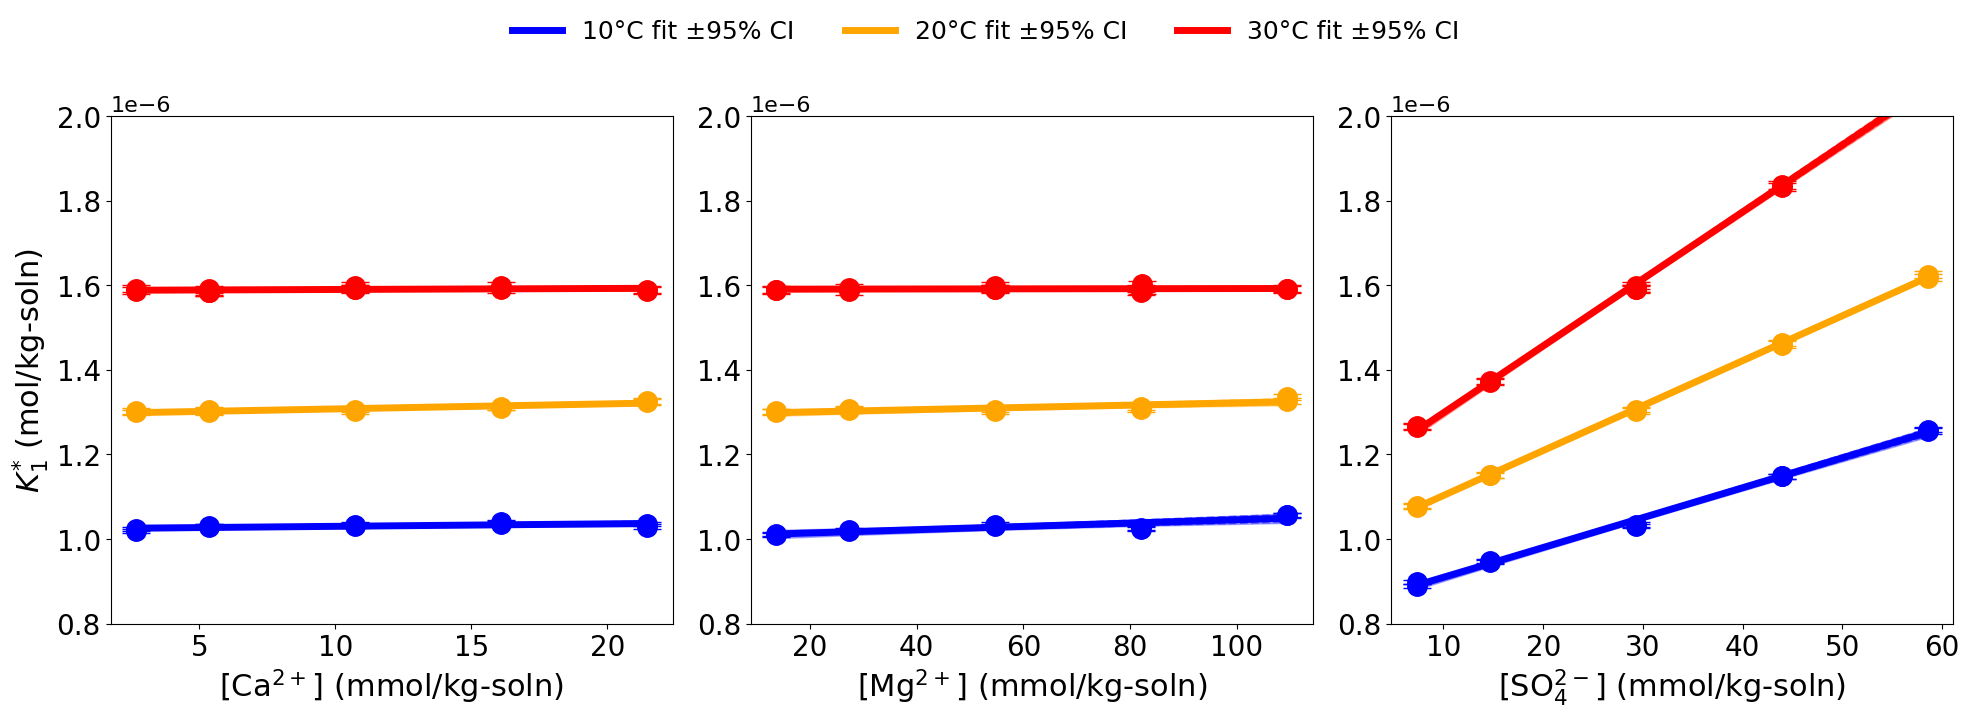

   Ion Temperature (°C)   K      Slope  Slope_SEM Slope_95CI Slope_pvalue  \
0   Ca        1.000e+01  K1  5.879e-10  2.237e-10  5.158e-10    3.027e-02   
1   Ca        2.000e+01  K1  1.199e-09  1.520e-10  3.386e-10    1.333e-05   
2   Ca        3.000e+01  K1  2.357e-10  2.071e-10  4.512e-10    2.774e-01   
3   Mg        1.000e+01  K1  3.891e-10  7.676e-11  1.770e-10    9.655e-04   
4   Mg        2.000e+01  K1  2.669e-10  5.920e-11  1.365e-10    1.980e-03   
5   Mg        3.000e+01  K1  1.641e-11  4.236e-11  9.229e-11    7.052e-01   
6  SO4        1.000e+01  K1  7.062e-09  1.361e-10  3.139e-10    2.110e-11   
7  SO4        2.000e+01  K1  1.062e-08  6.085e-11  1.403e-10    1.299e-15   
8  SO4        3.000e+01  K1  1.583e-08  1.595e-10  3.554e-10    2.638e-16   

   Intercept Intercept_SE Intercept_95CI Intercept_Lower Intercept_Upper  \
0  1.024e-06    2.954e-09      6.812e-09       1.017e-06       1.031e-06   
1  1.296e-06    1.861e-09      4.147e-09       1.292e-06       1.300e-06   
2

/var/folders/rp/6325jg2164gg259yvxgz1lzm0000gn/T/ipykernel_95154/1864710392.py:176: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  results_df[numeric_cols] = results_df[numeric_cols].applymap(


In [40]:
# Figure 3
#
# Compare the selected dissociation constant across ion compositions and
# temperatures. Experimental uncertainties are defined below.

pK_column = 'K1'
pK_column_titles = {'K1': '$K_1^{*}$', 'K2': '$K_2^{*}$'}

dat = dat.iloc[0:102]

# Experimental errors, see Supplementary material Appendix A
pK1_experr = 2.252e-3
pK2_experr =  3.109e-3

ions = ["Ca", "Mg", "SO4"]
ion_charge = {'Ca': 2, 'Mg': 2, 'SO4': 2}

ion_labels = {'Ca': 'Ca$^{2+}$', 'Mg': 'Mg$^{2+}$', 'SO4': 'SO$_4^{2-}$'}


temps = dat['Temperature'].unique()
colors = ["blue", "orange", "red", "green", "purple", "brown"]

results = []

# === 1x3 subplot layout ===
fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=False)

# === Plot settings ===
fontsize_labels = 22
fontsize_ticks = 20
fontsize_legend = 18
fontsize_title = 24
marker_size = 14
line_width = 5
conf_alpha = 0.3
error_bar_width = 4
error_bar_capsize = 10

for ax, ion in zip(axes, ions):
    data_ion = dat[dat['Ion'] == ion]
    used_labels = set()

    for idx, temp in enumerate(temps):
        data = data_ion[data_ion['Temperature'] == temp].dropna(subset=[pK_column])
        if len(data) > 1:

            data['Conc'] = round(data['Conc']*1000, 2)
            x = data['Conc'].values
            y = data[pK_column].values

            # --- Error propagation ---
            if pK_column in ['K1', 'K2']:
                pK_err = pK1_experr if pK_column == 'K1' else pK2_experr
                yerr = y * np.log(10) * pK_err
            else:
                pK_err = pK1_experr if pK_column == 'pK1' else pK2_experr
                yerr = pK_err

            ax.errorbar(x, y, yerr=yerr, fmt='none',
                        ecolor=colors[idx % len(colors)],
                        capsize=error_bar_capsize,
                        elinewidth=error_bar_width)

            # --- Linear regression ---
            res = linregress(x, y)
            y_fit = res.intercept + res.slope * x

            # --- Residual statistics ---
            n = len(x)
            x_mean = np.mean(x)
            df = n - 2
            t_crit = stats.t.ppf(0.975, df)
            s = np.sqrt(np.sum((y - y_fit) ** 2) / df)

            # --- Intercept standard error ---
            se_intercept = s * np.sqrt(
                1/n + (x_mean**2 / np.sum((x - x_mean)**2))
            )

            intercept_95CI = t_crit * se_intercept
            intercept_upper = res.intercept + intercept_95CI
            intercept_lower = res.intercept - intercept_95CI

            # --- Slope 95% CI ---
            total_slope_error = t_crit * res.stderr
            slope_upper = res.slope + total_slope_error
            slope_lower = res.slope - total_slope_error

            # --- 95% CI band ---
            se_fit = s * np.sqrt(1/n + (x - x_mean)**2 / np.sum((x - x_mean)**2))
            y_upper = y_fit + t_crit * se_fit
            y_lower = y_fit - t_crit * se_fit

            ax.fill_between(x, y_lower, y_upper,
                            color=colors[idx % len(colors)],
                            alpha=conf_alpha)

            # --- ±1 SEM slope lines ---
            y_fit_plus = (res.slope + res.stderr) * x + res.intercept
            y_fit_minus = (res.slope - res.stderr) * x + res.intercept
            ax.plot(x, y_fit_plus, '--', color=colors[idx % len(colors)], alpha=0.5)
            ax.plot(x, y_fit_minus, '--', color=colors[idx % len(colors)], alpha=0.5)

            # --- Scatter ---
            ax.plot(x, y, 'o', color=colors[idx % len(colors)], markersize=marker_size)
            ax.set_ylim(0.8e-6,2e-6)

            # --- Fit line ---
            ax.plot(x, y_fit, '-', color=colors[idx % len(colors)],
                    linewidth=line_width,
                    label=f'{temp}°C fit ±95% CI')

            # --- Maximum K error calculations ---
            max_conc = np.max(x)
            max_K_error_from_slope = total_slope_error * max_conc
            max_K_error_exp = np.max(y * np.log(10) * pK_err)

            # --- Store results ---
            results.append({
                "Ion": ion,
                "Temperature (°C)": temp,
                "K": pK_column,
                "Slope": res.slope,
                "Slope_SEM": res.stderr,
                "Slope_95CI": total_slope_error,
                "Slope_pvalue": res.pvalue,
                "Intercept": res.intercept,
                "Intercept_SE": se_intercept,
                "Intercept_95CI": intercept_95CI,
                "Intercept_Lower": intercept_lower,
                "Intercept_Upper": intercept_upper,
                "R²": res.rvalue**2,
                "Max_K_error_from_slope": max_K_error_from_slope,
                "Max_K_error_experimental": max_K_error_exp
            })

    # Axis labels
    if ion == 'SO4':
        ax.set_xlabel('[SO$_4^{2-}$] (mmol/kg-soln)', fontsize=fontsize_labels)
    else:
        ax.set_xlabel(f'[{ion}$^{{{ion_charge.get(ion, "")}+}}$] (mmol/kg-soln)',
                      fontsize=fontsize_labels)

    ax.tick_params(axis='both', labelsize=fontsize_ticks)

axes[0].set_ylabel(f'{pK_column_titles[pK_column]} (mol/kg-soln)',
                   fontsize=fontsize_labels)

# Legend
handles, labels = [], []
for ax in axes:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

fig.legend(handles, labels, loc='upper center',
           bbox_to_anchor=(0.5, 1.05),
           ncol=3, fontsize=fontsize_legend,
           frameon=False)


plt.tight_layout()
plt.subplots_adjust(top=0.88)
fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_3.png', dpi=600, bbox_inches='tight')
plt.show()


# === Results DataFrame ===
results_df = pd.DataFrame(results)

# Format numeric columns
numeric_cols = results_df.select_dtypes(include='number').columns
results_df[numeric_cols] = results_df[numeric_cols].applymap(
    lambda x: f"{x:.3e}"
)

print(results_df)


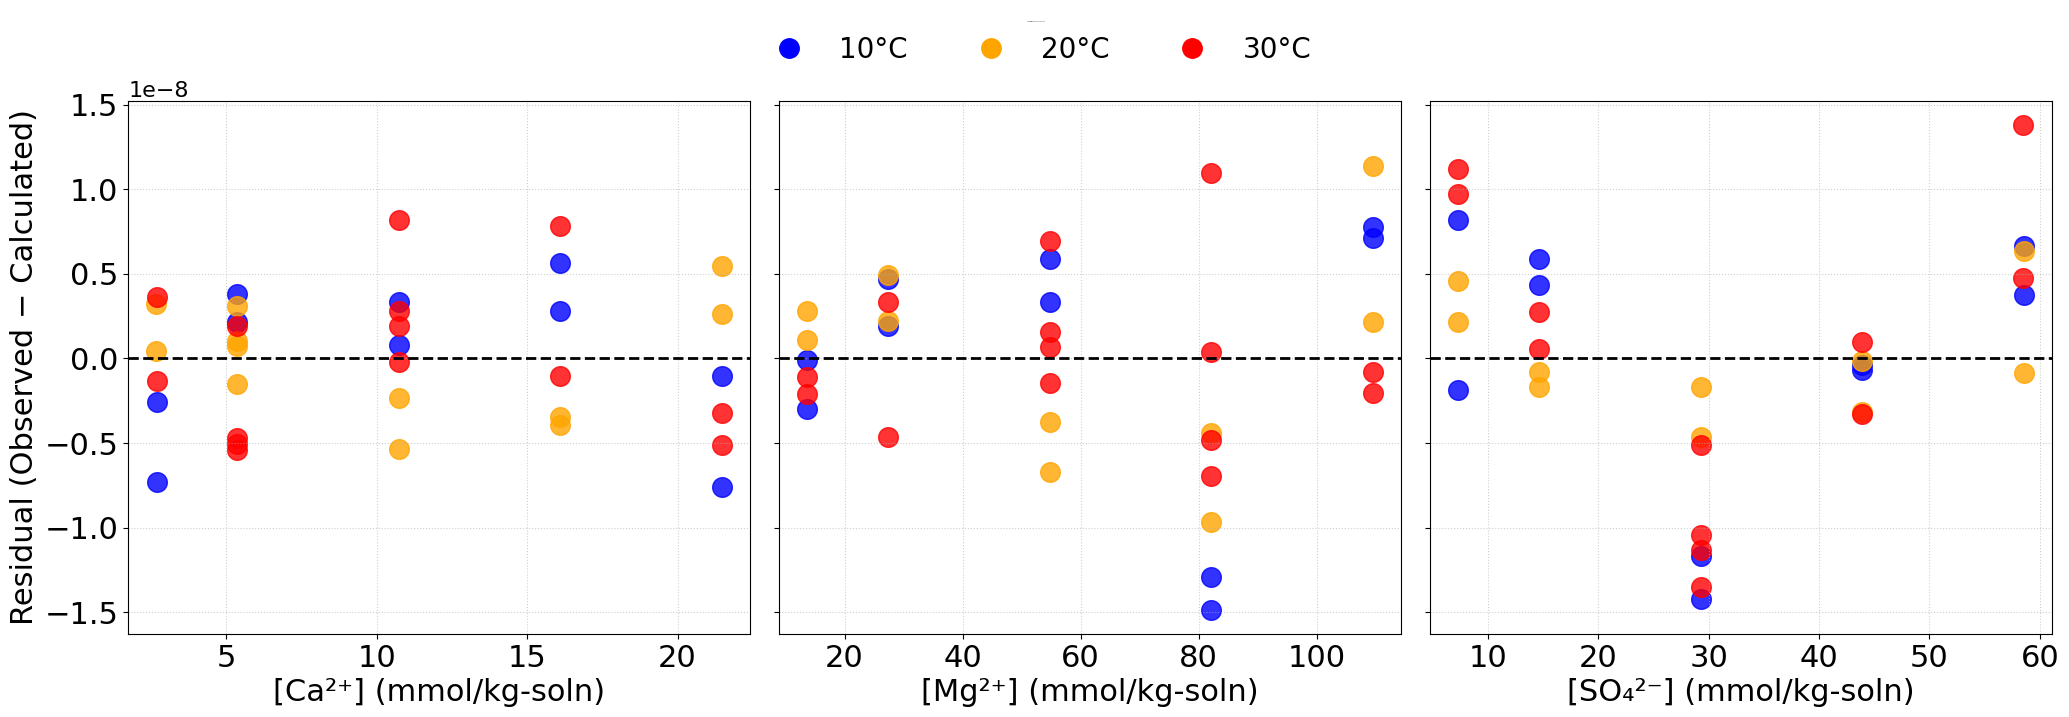

                      count          mean           std           min  \
Ion Temperature (°C)                                                    
Ca  10                 10.0  1.058791e-22  4.587148e-09 -7.621550e-09   
    20                 12.0  5.293956e-23  3.339314e-09 -5.356803e-09   
    30                 14.0 -4.537677e-23  4.584637e-09 -5.444659e-09   
Mg  10                 10.0  2.117582e-23  8.020727e-09 -1.484750e-08   
    20                 10.0  6.352747e-23  6.186600e-09 -9.671440e-09   
    30                 14.0 -1.058791e-22  4.707642e-09 -6.963308e-09   
SO4 10                 10.0 -8.470329e-23  7.616258e-09 -1.422727e-08   
    20                 10.0 -4.658681e-22  3.401636e-09 -4.675825e-09   
    30                 12.0  3.176374e-22  9.037690e-09 -1.350303e-08   

                               25%           50%           75%           max  
Ion Temperature (°C)                                                          
Ca  10               -2.190183e-09  1.

In [41]:
# Figure 4
#
# Fit concentration-dependent regressions and summarize the regression
# statistics for each ion and temperature.

pK_column = 'K1'

temp_color_map = {10: "blue", 20: "orange", 30: "red"}

# === Custom X-axis labels ===
custom_xlabels = {
    'Ca': '[Ca²⁺] (mmol/kg-soln)',
    'Mg': '[Mg²⁺] (mmol/kg-soln)',
    'SO4': '[SO₄²⁻] (mmol/kg-soln)'
}


# === Regression results ===
results = []

for ion in ions:
    data_ion = dat[dat['Ion'] == ion]
    for temp in sorted(data_ion['Temperature'].unique()):
        data_temp = data_ion[data_ion['Temperature'] == temp].dropna(subset=[pK_column])
        if len(data_temp) < 2:
            continue

        x = data_temp['Conc'].values * 1000  # mmol/kg
        y = data_temp[pK_column].values

        res = linregress(x, y)
        y_fit = res.intercept + res.slope * x

        n = len(x)
        df = n - 2
        t_crit = stats.t.ppf(0.975, df)
        s = np.sqrt(np.sum((y - y_fit) ** 2) / df)

        results.append({
            "Ion": ion,
            "Temperature (°C)": temp,
            "Slope": res.slope,
            "Intercept": res.intercept,
            "SEM_slope": res.stderr,
            "Total_Slope_Error_95CI": t_crit * res.stderr,
            "R²": res.rvalue ** 2,
        })

results_df = pd.DataFrame(results)

# === Plot setup: 1×3 (Ca, Mg, SO₄) ===
fig, axes = plt.subplots(1, 3, figsize=(21, 7), sharey=True)
fontsize_labels = 22
fontsize_ticks = 22
fontsize_title = 22
marker_size = 100

residuals_all = []

for ax, ion in zip(axes, ions):
    data_target = dat[dat['Ion'] == ion].dropna(subset=[pK_column])
    data_target['Conc'] = data_target['Conc'] * 1000  # mmol/kg

    for _, row in results_df[results_df['Ion'] == ion].iterrows():
        temp = row['Temperature (°C)']
        slope = row['Slope']
        intercept = row['Intercept']

        temp_data = data_target[data_target['Temperature'] == temp]
        if len(temp_data) < 2:
            continue

        x = temp_data['Conc'].values
        y_obs = temp_data[pK_column].values
        y_calc = intercept + slope * x
        residuals = y_obs - y_calc

        n = len(x)
        df = n - 2
        t_crit = stats.t.ppf(0.975, df)
        s = np.sqrt(np.sum((y_obs - y_calc) ** 2) / df)
        se_fit = s * np.sqrt(1 / n + (x - np.mean(x)) ** 2 / np.sum((x - np.mean(x)) ** 2))

        res_upper = t_crit * se_fit
        res_lower = -t_crit * se_fit

        temp_df = pd.DataFrame({
            'Ion': ion,
            'Temperature (°C)': temp,
            'Conc (mmol/kg-soln)': x,
            'Residual': residuals,
            'Residual_Upper_95CI': res_upper,
            'Residual_Lower_95CI': res_lower
        })
        residuals_all.append(temp_df)

        color = temp_color_map.get(temp, 'gray')

        ax.scatter(x, residuals, color=color, s=marker_size*2, alpha=0.8, label=f"{temp}°C")


    ax.axhline(0, color='black', linestyle='--', linewidth=2)
    ax.set_xlabel(custom_xlabels.get(ion, f"[{ion}] (mmol/kg-soln)"), fontsize=fontsize_labels)
    ax.tick_params(axis='both', labelsize=fontsize_ticks)
    ax.grid(True, linestyle=':', alpha=0.6)

axes[0].set_ylabel('Residual (Observed − Calculated)', fontsize=fontsize_labels)
# === Shared legend ===
handles, labels = axes[0].get_legend_handles_labels()

temp_handles = [
    Line2D(
        [0], [0],
        marker='o', linestyle='None',
        markerfacecolor=color, markeredgecolor=color,
        markersize=14,
        label=f'{temp}°C'
    )
    for temp, color in temp_color_map.items()
]
# Combine and build legend
handles = temp_handles
labels = [h.get_label() for h in handles]

fig.legend(
    handles, labels, title='Temperature and 95% CI',
    loc='upper center', bbox_to_anchor=(0.5, 1.05),
    ncol=3, fontsize=20, frameon=False, title_fontsize=0
)

# === Shared legend ===
handles, labels = axes[0].get_legend_handles_labels()


plt.tight_layout()
plt.subplots_adjust(top=0.9)
fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_4.png', dpi=600, bbox_inches='tight')
plt.show()

# === Residual summary (optional) ===
residuals_df = pd.concat(residuals_all, ignore_index=True)
print(residuals_df.groupby(['Ion', 'Temperature (°C)'])['Residual'].describe())


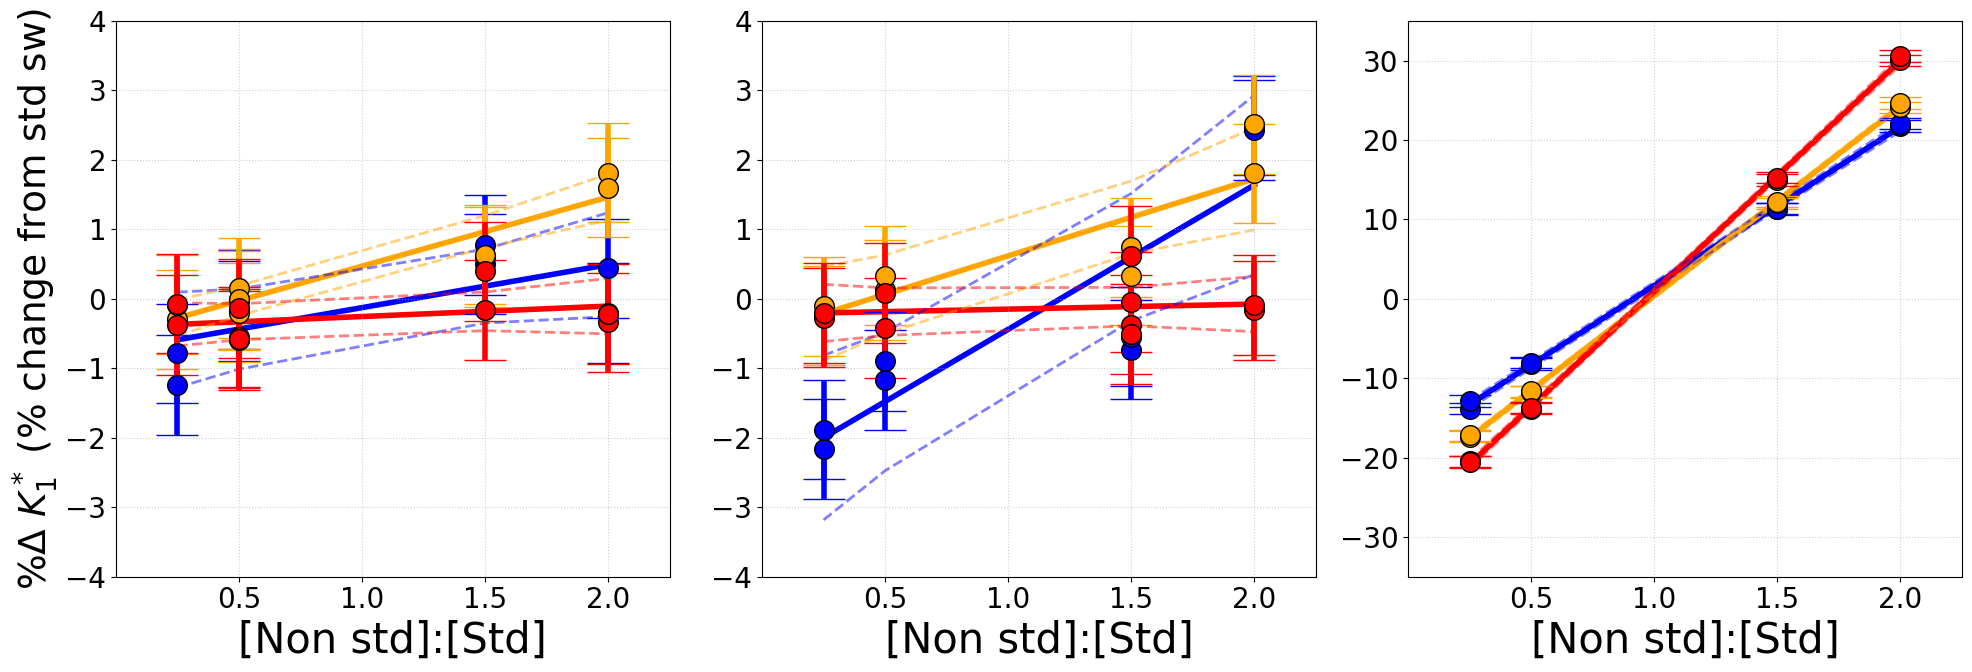

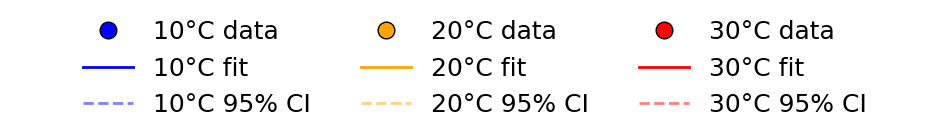

==== ΔK% Range Across Temperatures (Each Ion) ====

Ion: Ca
  Min ΔK% = -1.818638e+00
  Max ΔK% = 1.240743e+00
  Range   = 3.059381e+00

Ion: Mg
  Min ΔK% = -2.511296e+00
  Max ΔK% = 2.162678e+00
  Range   = 4.673974e+00

Ion: SO4
  Min ΔK% = -3.060361e+01
  Max ΔK% = 2.055919e+01
  Range   = 5.116280e+01


In [42]:
# === FIGURE 7 – ΔK (% difference from reference) ===

# Specify parameter
pK_column = 'K1'   # K1 or K2

# Y-limits for percent difference
custom_ylim = {
    'Ca':  (-4, 4),
    'Mg':  (-4, 4),
    'SO4': (-35, 35)
}


temps = sorted(dat['Temperature'].unique())
temp_colors = {10: 'blue', 20: 'orange', 30: 'red'}

# === Style settings ===
fontsize_labels = 30
fontsize_ticks = 20
fontsize_legend = 18
marker_size = 100
line_width = 4
error_bar_width = 4
error_bar_capsize = 15

# ΔpK experimental error
pK_err = pK2_experr       
delta_Kpct_err = np.log(10) * pK_err * 100     # constant % error

# === Figure ===
fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=False)
legend_handles = []

for ax, ion_target in zip(axes, ions):

    for temp in temps:
        data = dat[(dat['Ion'] == ion_target) &
                   (dat['Temperature'] == temp)].dropna(subset=[pK_column])

        if len(data) < 2:
            continue

        x = data['Conc Multiplier'] 
        y = data[pK_column].values
        conc_mult = data['Conc Multiplier'].values

        # Reference K where Conc Multiplier == 1
        ref_data = data[data['Conc Multiplier'] == 1]
        if len(ref_data) == 0:
            continue
        y_ref = ref_data[pK_column].values[0]

        # ΔK% = (K - Kref)/Kref * 100
        delta_y = (y - y_ref) / y_ref * 100

        # Omit reference point
        mask = conc_mult != 1
        x = x[mask]
        delta_y = delta_y[mask]

        if len(delta_y) < 2:
            continue

        # Linear regression
        res = linregress(x, delta_y)
        y_fit = res.intercept + res.slope * x

        # Residual STD error
        n = len(x)
        df = n - 2
        t_crit = stats.t.ppf(0.975, df)
        s = np.sqrt(np.sum((delta_y - y_fit)**2) / df)

        x_mean = np.mean(x)
        se_fit = s * np.sqrt(1/n + (x - x_mean)**2 / np.sum((x - x_mean)**2))
        y_upper = y_fit + t_crit * se_fit
        y_lower = y_fit - t_crit * se_fit

        # Fit line
        ax.plot(x, y_fit, '-', color=temp_colors[temp],
                linewidth=line_width, zorder=1)

        # Error bars (ΔK% uncertainty)
        ax.errorbar(
            x, delta_y,
            yerr=delta_Kpct_err,
            fmt='none',
            ecolor=temp_colors[temp],
            capsize=error_bar_capsize,
            elinewidth=error_bar_width,
            zorder=2
        )

        # Data points
        ax.scatter(
            x, delta_y,
            color=temp_colors[temp],
            s=marker_size * 2,
            edgecolors='black',
            zorder=3
        )

        # 95% CI
        ax.plot(x, y_upper, '--', color=temp_colors[temp], linewidth=2, alpha=0.5)
        ax.plot(x, y_lower, '--', color=temp_colors[temp], linewidth=2, alpha=0.5)

        # Add legend entries only once
        if ion_target == ions[0]:
            legend_handles.append(Line2D([0], [0], marker='o', color='w',
                                         markerfacecolor=temp_colors[temp],
                                         markeredgecolor='black',
                                         markersize=12, label=f"{temp}°C data"))
            legend_handles.append(Line2D([0], [0], color=temp_colors[temp],
                                         linewidth=2, label=f"{temp}°C fit"))
            legend_handles.append(Line2D([0], [0], color=temp_colors[temp],
                                         linewidth=2, linestyle='--',
                                         alpha=0.5, label=f"{temp}°C 95% CI"))

    # === Axis styling ===
    if ion_target == 'SO4':
        ax.set_xlabel('[Non std]:[Std]', fontsize=fontsize_labels)
    else:
        ax.set_xlabel('[Non std]:[Std]', fontsize=fontsize_labels)

    if ion_target == 'Ca':
        ax.set_ylabel(r'%$\Delta$ $K_1^*$ (% change from std sw)', fontsize=27)

    ax.tick_params(axis='both', labelsize=fontsize_ticks)
    ax.grid(True, linestyle=':', alpha=0.6)

    ax.set_ylim(custom_ylim[ion_target])
    ax.tick_params(axis='both', labelsize=fontsize_ticks)
    ax.grid(True, linestyle=':', alpha=0.6)

    ax.set_ylim(custom_ylim[ion_target])

    # === Custom x-axis ticks ===
    ax.set_xticks([0.5, 1, 1.5, 2])
    ax.set_xlim(0, 2.25)


# === Legend ===
figlegend, ax_leg = plt.subplots(figsize=(12, 1.5))
ax_leg.axis('off')
ax_leg.legend(handles=legend_handles, fontsize=fontsize_legend,
              ncol=3, loc='center', frameon=False)
fig.tight_layout()
plt.show()


print("==== ΔK% Range Across Temperatures (Each Ion) ====")

for ion_target in ions:
    delta_values = []

    for temp in temps:
        data = dat[(dat['Ion'] == ion_target) & (dat['Temperature'] == temp)]
        data = data.dropna(subset=[pK_column])

        if len(data) == 0:
            continue

        # reference value
        ref_data = data[data['Conc Multiplier'] == 1]
        if len(ref_data) == 0:
            continue

        y_ref = ref_data[pK_column].values[0]

        # compute ΔK% for all points at this temp
        y = data[pK_column].values
        delta_percent = 100 - (y / y_ref) * 100

        # append only non-reference values
        conc_mult = data['Conc Multiplier'].values
        delta_percent = delta_percent[conc_mult != 1]

        for val in delta_percent:
            delta_values.append(val)

    # after collecting all values for this ion:
    if len(delta_values) > 0:
        dk_min = np.min(delta_values)
        dk_max = np.max(delta_values)
        dk_range = dk_max - dk_min

        print(f"\nIon: {ion_target}")
        print(f"  Min ΔK% = {dk_min:.6e}")
        print(f"  Max ΔK% = {dk_max:.6e}")
        print(f"  Range   = {dk_range:.6e}")
    else:
        print(f"\nIon: {ion_target} — no ΔK% data found.")


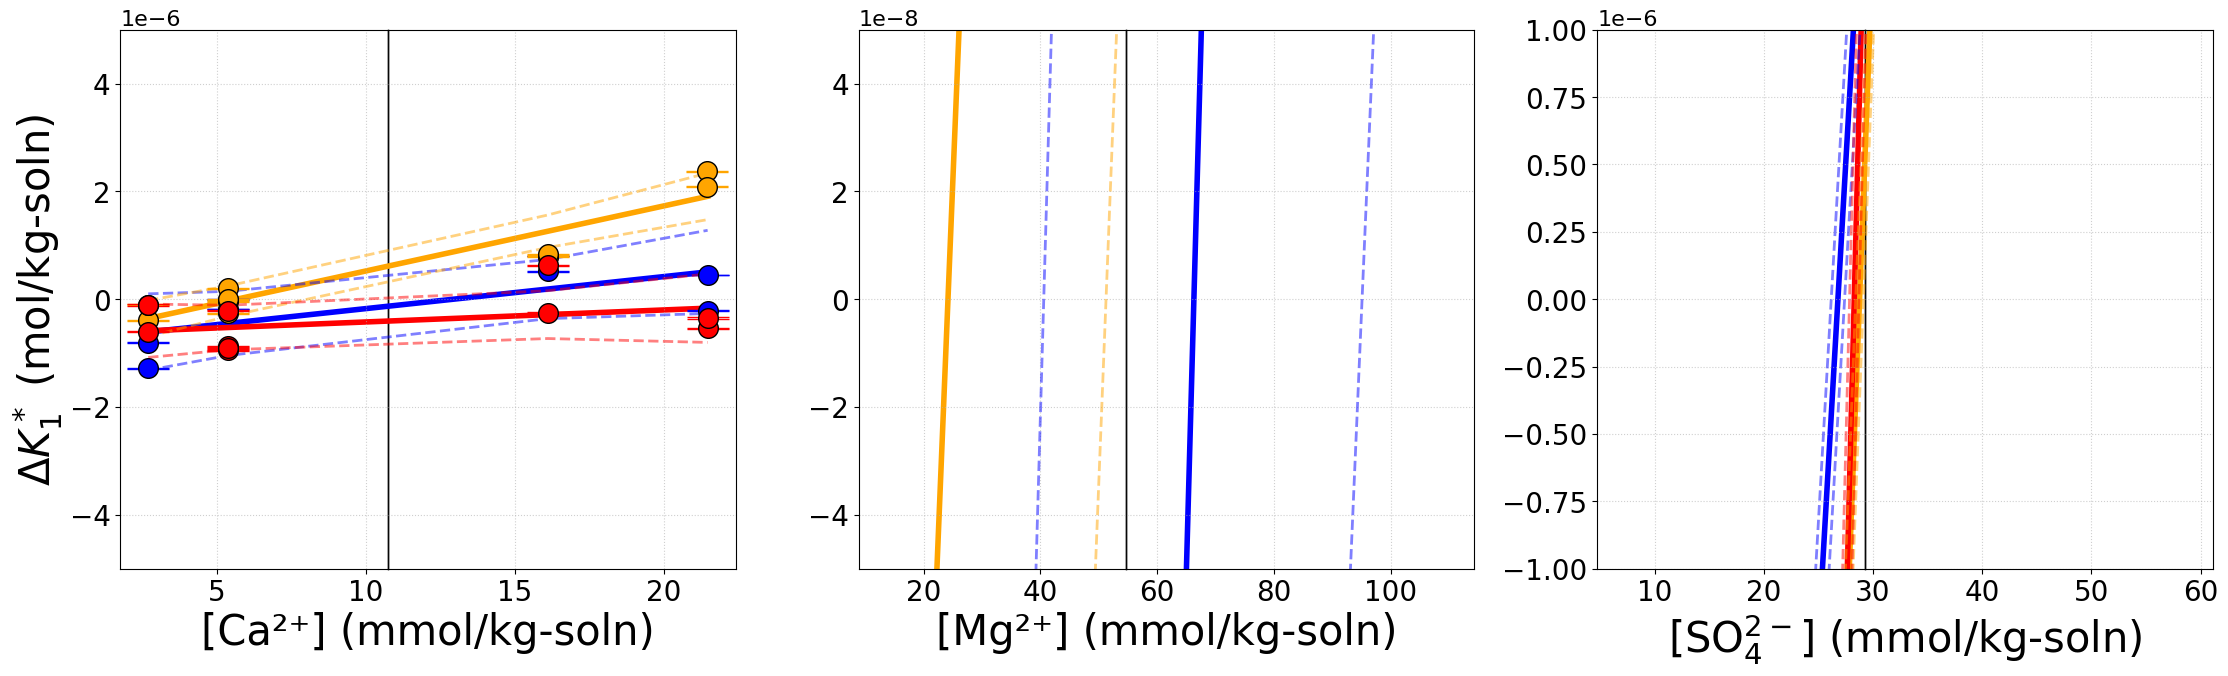

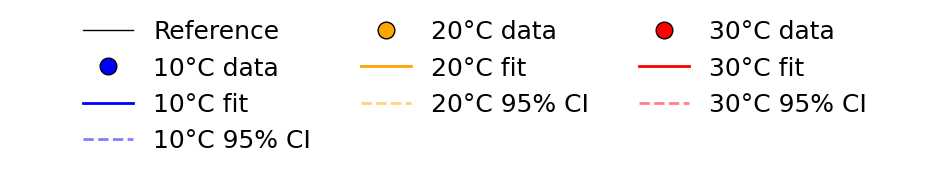


 SUMMARY STATISTICS — Figure 4
   (Slope in scientific notation)

Ion  Temperature (°C)     Slope  Intercept    R²
 Ca                10 5.935e-08       -0.0 0.486
 Ca                20 1.206e-07       -0.0 0.903
 Ca                30 2.228e-08       -0.0 0.128
 Mg                10 3.917e-08       -0.0 0.783
 Mg                20 2.640e-08       -0.0 0.759
 Mg                30 2.123e-09       -0.0 0.025
SO4                10 7.048e-07       -0.0 0.999
SO4                20 1.062e-06       -0.0 1.000
SO4                30 1.581e-06       -0.0 1.000


In [43]:
#Figure 5
# === User settings ===
pK_column = 'K1'

if pK_column == 'pK1':
    custom_ylim = {
        'Ca': (-0.01, 0.01),
        'Mg': (-0.015, 0.015),
        'SO4': (-0.135, 0.135)
    }
elif pK_column == 'K1':
    custom_ylim = {
        'Ca': (-0.5e-5, 0.5e-5),
        'Mg': (-0.5e-7, 0.5e-7),
        'SO4': (-1e-6, 1e-6)
    }
elif pK_column == 'K2':
    custom_ylim = {
        'Ca': (-0.25e-9, 0.25e-9),
        'Mg': (-1e-9, 1e-9),
        'SO4': (-0.3e-9, 0.3e-9)
    }

# === FIGURE ===
fig, axes = plt.subplots(1, 3, figsize=(27, 7), sharey=False)
legend_handles = []

# Add reference line to legend ONCE
legend_handles.append(
    Line2D([0], [0],
           color='black',
           linewidth=1,
           linestyle='-',
           label='Reference')
)

all_results = []

for ax, ion_target in zip(axes, ions):

    for temp in temps:
        data = dat[(dat['Ion'] == ion_target) & (dat['Temperature'] == temp)].dropna(subset=[pK_column])

        if len(data) > 1:
            x = data['Conc'].values * 1000
            y = data[pK_column].values
            conc_mult = data['Conc Multiplier'].values

            ref_data = data[data['Conc Multiplier'] == 1]
            if len(ref_data) == 0:
                continue

            y_ref = ref_data[pK_column].values[0]

            # === Reference vertical line (FIXED) ===
            x_ref = ref_data['Conc'].values[0] * 1000
            ax.axvline(
                x=x_ref,
                color='black',
                linestyle='-',
                linewidth=1,
                alpha=0.7,
                zorder=0,
                ymin=0, ymax=1,
                clip_on=False
            )

            delta_y = (y - y_ref) * 100

            mask = conc_mult != 1
            x = x[mask]
            delta_y = delta_y[mask]

            if len(delta_y) < 2:
                continue

            res = linregress(x, delta_y)
            y_fit = res.intercept + res.slope * x

            n = len(x)
            df = n - 2
            t_crit = stats.t.ppf(0.975, df)
            s = np.sqrt(np.sum((delta_y - y_fit) ** 2) / df)

            x_mean = np.mean(x)
            se_fit = s * np.sqrt(1/n + (x - x_mean)**2 / np.sum((x - x_mean)**2))

            y_upper = y_fit + t_crit * se_fit
            y_lower = y_fit - t_crit * se_fit

            ax.plot(x, y_fit, '-', color=temp_colors[temp], linewidth=line_width, zorder=1)

            pK_err = pK2_experr
            delta_K_err = np.abs(y_ref) * np.log(10) * pK_err

            ax.errorbar(x, delta_y, yerr=delta_K_err, fmt='none',
                        ecolor=temp_colors[temp], capsize=error_bar_capsize,
                        elinewidth=error_bar_width, zorder=2)

            ax.scatter(x, delta_y, color=temp_colors[temp], s=marker_size*2,
                       edgecolors='black', zorder=3)

            ax.plot(x, y_upper, '--', color=temp_colors[temp], linewidth=2, alpha=0.5)
            ax.plot(x, y_lower, '--', color=temp_colors[temp], linewidth=2, alpha=0.5)

            if ion_target == 'Ca':
                legend_handles.append(Line2D([0], [0], marker='o', color='w',
                                             markerfacecolor=temp_colors[temp], markersize=12,
                                             markeredgecolor='black', label=f"{temp}°C data"))
                legend_handles.append(Line2D([0], [0], color=temp_colors[temp],
                                             linewidth=2, label=f"{temp}°C fit"))
                legend_handles.append(Line2D([0], [0], color=temp_colors[temp],
                                             linewidth=2, linestyle='--', alpha=0.5,
                                             label=f"{temp}°C 95% CI"))

            all_results.append({
                "Ion": ion_target,
                "Temperature (°C)": temp,
                "Slope": res.slope,
                "Intercept": res.intercept,
                "R²": res.rvalue**2
            })

    ax.set_xlabel(f'[{ion_target}²⁺] (mmol/kg-soln)', fontsize=fontsize_labels)

    if ion_target == 'Ca':
        ax.set_ylabel(r'$\Delta$$K_1^*$ (mol/kg-soln)', fontsize=fontsize_labels)
    elif ion_target == 'SO4':
        ax.set_xlabel(r'[SO$_4^{2-}$] (mmol/kg-soln)', fontsize=fontsize_labels)

    ax.tick_params(axis='both', labelsize=fontsize_ticks)
    ax.grid(True, linestyle=':', alpha=0.6)

    # === LOCK Y LIMITS (FINAL FIX) ===
    if ion_target in custom_ylim:
        ax.set_ylim(*custom_ylim[ion_target])
        ax.set_autoscale_on(False)

# === Legend figure ===
figlegend, ax_leg = plt.subplots(figsize=(12, 1.5))
ax_leg.axis('off')
ax_leg.legend(handles=legend_handles, fontsize=fontsize_legend,
              ncol=3, loc='center', frameon=False)

plt.show()
# ======================================================
# === SUMMARY STATISTICS — Figure 4 (Slope in Sci-Notation)
# ======================================================

summary_df = pd.DataFrame(all_results)

# Convert slope to scientific notation as a string
summary_df['Slope'] = summary_df['Slope'].apply(lambda x: f"{x:.3e}")

# Round other fields
summary_df['Intercept'] = summary_df['Intercept'].round(3)
summary_df['R²'] = summary_df['R²'].round(3)

print("\n===============================")
print(" SUMMARY STATISTICS — Figure 4")
print("   (Slope in scientific notation)")
print("===============================\n")

print(summary_df.to_string(index=False))


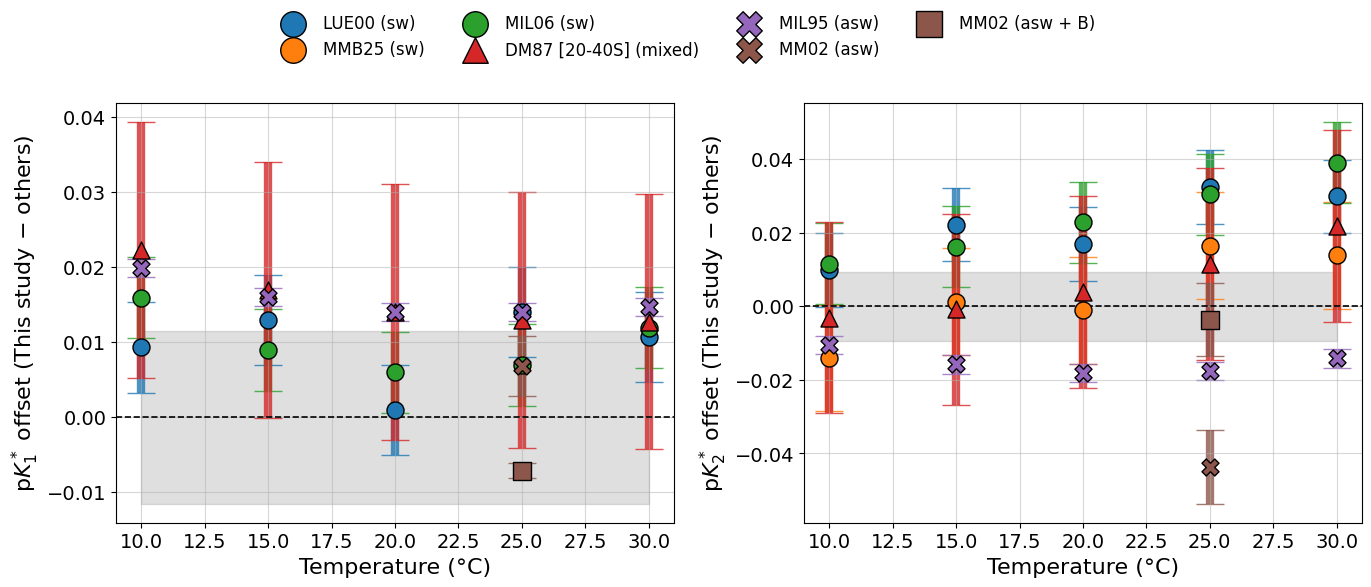


=== Mean ΔpK offsets by temperature ===

Mean ΔpK1 (This study − others):
 T_C    delta
  10 0.016812
  15 0.013669
  20 0.008726
  25 0.010289
  30 0.012490

Mean ΔpK2 (This study − others):
 T_C    delta
  10 0.009815
  15 0.011241
  20 0.012578
  25 0.022253
  30 0.023753


In [44]:
# Figure 6
#
# Compare the Richardson results with the selected reference formulations.

rich1 = comparestdpk[comparestdpk['Formulation'] == 'Richardson'][['T_C', 'pK1']]
rich2 = comparestdpk[comparestdpk['Formulation'] == 'Richardson'][['T_C', 'pK2']]

rich1 = rich1.rename(columns={'pK1': 'pK1_R'})
rich2 = rich2.rename(columns={'pK2': 'pK2_R'})


rich_pK1_err = 0.011521803
rich_pK2_err = 0.009375115

# =====================================================
# === Define formulations and colors ===
# =====================================================
forms = [f for f in comparestdpk['Formulation'].dropna().unique() if f != 'Richardson']

cmap = plt.get_cmap('tab10')
color_map = {form: cmap(i % 10) for i, form in enumerate(forms)}

# =====================================================
# === Define media markers ===
# =====================================================
media_marker = {'sw': 'o', 'mixed': '^', 'asw': 'X', 'asw + b': 's'}

# =====================================================
# === Create figure ===
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=False)

# =====================================================
# === Helper plotting function ===
# =====================================================
def plot_deltas(ax, pk_col, error_col, rich_df, ylabel):

    # -------------------------------
    # Manual Richardson uncertainty band
    # -------------------------------
    if pk_col == 'pK1':
        rich_err = rich_pK1_err
    else:
        rich_err = rich_pK2_err

    T_unique = sorted(rich_df['T_C'].unique())

    ax.fill_between(
        T_unique,
        [-rich_err]*len(T_unique),
        [ rich_err]*len(T_unique),
        color='gray',
        alpha=0.25,
        zorder=0
    )

    # -------------------------------
    # Plot each formulation
    # -------------------------------
    for form in forms:

        df_cols = ['T_C', pk_col, error_col]
        if 'media' in comparestdpk.columns:
            df_cols.append('media')

        df = comparestdpk[comparestdpk['Formulation'] == form][df_cols]
        merged = pd.merge(df, rich_df, on='T_C', how='inner')

        if merged.empty:
            continue

        merged = merged.sort_values('T_C')
        merged['delta'] = merged[pk_col] - merged[f'{pk_col}_R']
        merged['delta_err'] = merged[error_col]

        # ---- Plot by media type ----
        if 'media' in merged.columns:

            for media_type, group in merged.groupby('media'):
                marker = media_marker.get(media_type.lower(), 'o')

                # Error bars first
                ax.errorbar(group['T_C'], group['delta'],
                            yerr=group['delta_err'],
                            fmt='none',
                            ecolor=color_map[form],
                            elinewidth=6,
                            capsize=10,
                            alpha=0.8,
                            zorder=1)

                # Points on top
                ax.scatter(group['T_C'], group['delta'],
                           s=150,
                           color=color_map[form],
                           marker=marker,
                           edgecolors='k',
                           alpha=1,
                           zorder=3,
                           label=f"{form} ({media_type})")

        else:
            # Error bars
            ax.errorbar(merged['T_C'], merged['delta'],
                        yerr=merged['delta_err'],
                        fmt='none',
                        ecolor=color_map[form],
                        elinewidth=6,
                        capsize=8,
                        alpha=1,
                        zorder=1)

            # Points
            ax.scatter(merged['T_C'], merged['delta'],
                       s=140,
                       color=color_map[form],
                       marker='o',
                       edgecolors='k',
                       alpha=1,
                       zorder=3,
                       label=form)

    # Zero reference line
    ax.axhline(0, color='k', linestyle='--', linewidth=1.2)

    ax.set_xlabel('Temperature (°C)', fontsize=16)
    ax.set_ylabel(ylabel, fontsize=16)
    ax.grid(alpha=0.5)
    ax.tick_params(labelsize=14)


# =====================================================
# === Plot panels ===
# =====================================================
plot_deltas(
    axes[0],
    'pK1',
    'pK1_Error',
    rich1,
    'p$K_1^*$ offset (This study − others)'
)

plot_deltas(
    axes[1],
    'pK2',
    'pK2_Error',
    rich2,
    'p$K_2^*$ offset (This study − others)'
)

# =====================================================
# === Combined legend ===
# =====================================================
handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))

legend_elements_media = [
    Line2D([0], [0], marker='o', color='w', label='sw',
           markerfacecolor='gray', markersize=12, markeredgecolor='k'),
    Line2D([0], [0], marker='^', color='w', label='mixed',
           markerfacecolor='gray', markersize=12, markeredgecolor='k'),
    Line2D([0], [0], marker='X', color='w', label='asw',
           markerfacecolor='gray', markersize=12, markeredgecolor='k'),
    Line2D([0], [0], marker='s', color='w', label='asw + B',
           markerfacecolor='gray', markersize=12, markeredgecolor='k')
]

fig.legend(
    list(unique.values()) + legend_elements_media,
    list(unique.keys()),
    loc='upper center',
    ncol=4,
    fontsize=12,
    markerscale=1.5,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.87])
fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_6.png', dpi=600, bbox_inches='tight')
plt.show()

# =====================================================
# === Mean absolute ΔpK offsets ===
# =====================================================
print("\n=== Mean ΔpK offsets by temperature ===")

def compute_mean_offsets(pk_col, rich_df):

    df_list = []

    for form in forms:

        df_cols = ['T_C', pk_col]
        if 'media' in comparestdpk.columns:
            df_cols.append('media')

        df = comparestdpk[comparestdpk['Formulation'] == form][df_cols]
        merged = pd.merge(df, rich_df, on='T_C', how='inner')

        if merged.empty:
            continue

        merged['delta'] = abs(merged[pk_col] - merged[f'{pk_col}_R'])
        df_list.append(merged[['T_C', 'delta']])

    if not df_list:
        return None

    all_deltas = pd.concat(df_list)
    result = all_deltas.groupby('T_C')['delta'].mean().reset_index()

    return result


mean_pk1 = compute_mean_offsets('pK1', rich1)
mean_pk2 = compute_mean_offsets('pK2', rich2)

print("\nMean ΔpK1 (This study − others):")
print(mean_pk1.to_string(index=False))

print("\nMean ΔpK2 (This study − others):")
print(mean_pk2.to_string(index=False))


 Ca |   10°C | Kgen         | Average ΔK = -1.485%
 Ca |   10°C | MARCHEMSPEC  | Average ΔK = -1.161%
 Ca |   10°C | PyMyAMI      | Average ΔK = -0.032%
 Ca |   20°C | Kgen         | Average ΔK = -1.901%
 Ca |   20°C | MARCHEMSPEC  | Average ΔK = -0.322%
 Ca |   20°C | PyMyAMI      | Average ΔK = -0.046%
 Ca |   30°C | Kgen         | Average ΔK = -1.952%
 Ca |   30°C | MARCHEMSPEC  | Average ΔK =  0.522%
 Ca |   30°C | PyMyAMI      | Average ΔK = -0.008%
 Mg |   10°C | Kgen         | Average ΔK = -0.576%
 Mg |   10°C | MARCHEMSPEC  | Average ΔK = -0.839%
 Mg |   10°C | PyMyAMI      | Average ΔK = -0.094%
 Mg |   20°C | Kgen         | Average ΔK = -1.635%
 Mg |   20°C | MARCHEMSPEC  | Average ΔK = -0.285%
 Mg |   20°C | PyMyAMI      | Average ΔK = -0.054%
 Mg |   30°C | Kgen         | Average ΔK = -1.977%
 Mg |   30°C | MARCHEMSPEC  | Average ΔK =  0.602%
 Mg |   30°C | PyMyAMI      | Average ΔK = -0.008%
SO4 |   10°C | MARCHEMSPEC  | Average ΔK = -2.606%
SO4 |   10°C | PyMyAMI      | A

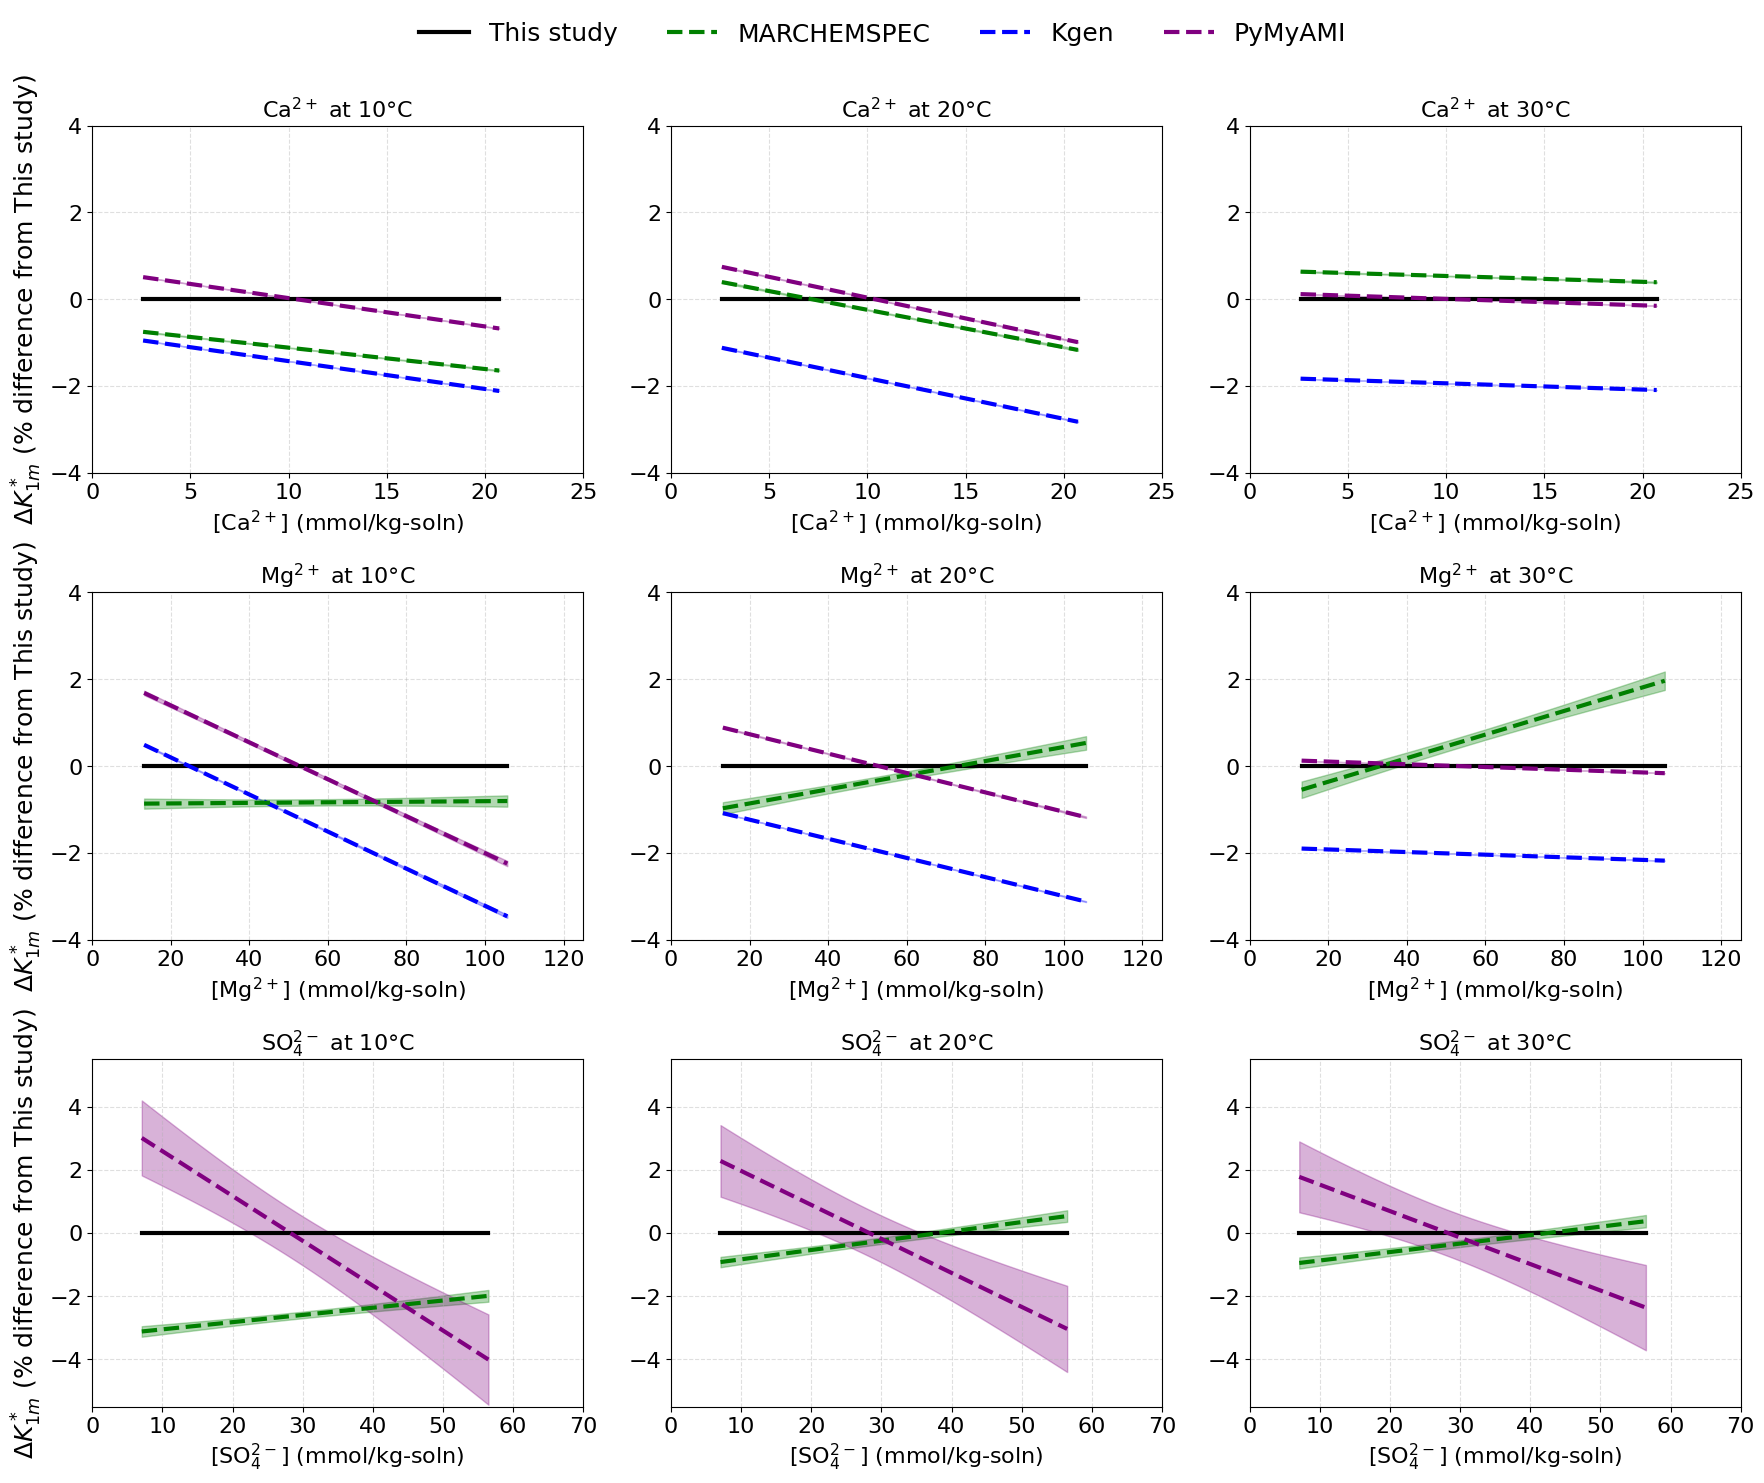

In [45]:
# Figure 8
#
# Compare concentration-dependent K1* and K2* responses across ions,
# temperatures, and model formulations.

ions = ['Ca', 'Mg', 'SO4']

temperatures = sorted(
    stdpk['T_C'].dropna().unique()
)

# ============================================================
# Marker + color maps
# ============================================================

marker_map = {
    'MARCHEMSPEC': 's',
    'Kgen': '^',
    'PyMyAMI': 'd'
}

color_map = {
    'MARCHEMSPEC': 'green',
    'Kgen': 'blue',
    'PyMyAMI': 'purple'
}

# ============================================================
# Axis limits
# ============================================================

xlim_map = {
    'Ca': (0, 25),
    'Mg': (0, 125),
    'SO4': (0, 70)
}

ylim_map = {
    'Ca': (-4, 4),
    'Mg': (-4, 4),
    'SO4': (-5.5, 5.5)
}

# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(18, 15),
    sharey=False
)

axes = axes.flatten()

# ============================================================
# Loop through ion × temperature
# ============================================================

for i, (ion, T) in enumerate(
    [(ion, T) for ion in ions for T in temperatures]
):

    ax = axes[i]

    # --------------------------------------------------------
    # Select ion
    # --------------------------------------------------------

    ion_data = stdpk[
        stdpk['Ion'].str.contains(
            ion,
            case=False,
            na=False
        )
    ].copy()

    # --------------------------------------------------------
    # Richardson data
    # --------------------------------------------------------

    rich = ion_data[
        ion_data['Formulation'] == 'Richardson'
    ].copy()

    # --------------------------------------------------------
    # Other formulations
    # --------------------------------------------------------

    others = ion_data[
        ion_data['Formulation'] != 'Richardson'
    ].copy()

    # Kgen is not available for SO4
    if ion == 'SO4':
        others = others[
            others['Formulation'] != 'Kgen'
        ]

    # ========================================================
    # 1. Richardson temperature-dependent K1 regression
    #
    # Absolute K1 = 10^(-pK1)
    #
    # K1_Richardson(C,T) = a + b*C
    # ========================================================

    rich_T = rich[
        (rich['T_C'] == T)
        & rich['Conc'].notna()
        & rich['pK1'].notna()
    ].copy()

    if rich_T.empty:
        continue

    X_rich = rich_T[
        'Conc'
    ].values.reshape(-1, 1)

    K_rich = (
        10 ** (
            -rich_T['pK1'].values
        )
    )

    # Fit Richardson absolute K1 regression
    reg_rich = LinearRegression().fit(
        X_rich,
        K_rich
    )

    # --------------------------------------------------------
    # Concentration range for Richardson regression
    # --------------------------------------------------------

    x_fit = np.linspace(
        X_rich.min(),
        X_rich.max(),
        100
    )

    # Richardson predicted K1
    K_rich_fit = reg_rich.predict(
        x_fit.reshape(-1, 1)
    )

    # ========================================================
    # 2. Richardson standard concentration
    # ========================================================

    std_rich = rich_T[
        np.isclose(
            rich_T['ConcMultiplier'],
            1.0
        )
    ]

    if std_rich.empty:
        raise ValueError(
            f"No Richardson standard concentration "
            f"found for {ion} at {T}°C."
        )

    conc_std = std_rich[
        'Conc'
    ].mean()

    # Richardson absolute K1 at standard composition
    K_rich_std = reg_rich.predict(
        np.array([[conc_std]])
    )[0]

    # ========================================================
    # 3. Richardson reference line
    #
    # Richardson is the reference.
    #
    # Therefore:
    #
    # ΔK_Richardson = 0%
    #
    # at every concentration.
    # ========================================================

    rich_percent_fit = np.zeros_like(
        x_fit
    )

    ax.plot(
        x_fit,
        rich_percent_fit,
        color='black',
        linewidth=3,
        label='This study'
    )

    # ========================================================
    # 4. Other formulations
    # ========================================================

    for name, df_form in others.groupby(
        'Formulation'
    ):

        df_T = df_form[
            (df_form['T_C'] == T)
            & df_form['Conc'].notna()
        ].copy()

        if df_T.empty:
            continue

        # ====================================================
        # MARCHEMSPEC / Kgen
        #
        # These provide absolute K1.
        #
        # K_model = 10^(-pK1)
        #
        # Richardson K1 is calculated at the exact same
        # concentration and temperature.
        #
        # ΔK (%) =
        #
        # 100 * [1 - K_model / K_Richardson]
        # ====================================================

        if name in [
            'Kgen',
            'MARCHEMSPEC'
        ]:

            df_T = df_T[
                df_T['pK1'].notna()
            ].copy()

            if df_T.empty:
                continue

            x_other = df_T[
                'Conc'
            ].values

            K1_other = (
                10 ** (
                    -df_T['pK1'].values
                )
            )

            valid = (
                np.isfinite(x_other)
                & np.isfinite(K1_other)
            )

            x_other = x_other[valid]
            K1_other = K1_other[valid]

            if len(x_other) == 0:
                continue

            # ------------------------------------------------
            # Richardson K1 at model concentrations
            # ------------------------------------------------

            K_richardson_at_other = (
                reg_rich.predict(
                    x_other.reshape(-1, 1)
                )
            )

            # ------------------------------------------------
            # Relative difference from Richardson
            # ------------------------------------------------

            y_other = (
                100
                * (
                     (
                        K1_other
                        / K_richardson_at_other
                    ) - 1
                )
            )

        # ====================================================
        # PyMyAMI
        #
        # PyMyAMI provides K1_ratio:
        #
        # K_PM(C,T) / K_PM,std(T)
        #
        # Richardson provides absolute K1, so calculate:
        #
        # K_Rich(C,T) / K_Rich,std(T)
        #
        # Then compare the two normalized responses:
        #
        # ΔK (%) =
        #
        # 100 * [
        #     1 -
        #     (
        #       K_PM_ratio
        #       /
        #       K_Rich_ratio
        #     )
        # ]
        # ====================================================

        elif name == 'PyMyAMI':

            df_T = df_T[
                df_T['K1_ratio'].notna()
            ].copy()

            if df_T.empty:
                continue

            x_other = df_T[
                'Conc'
            ].values

            K_pymyami_ratio = df_T[
                'K1_ratio'
            ].values.astype(float)

            valid = (
                np.isfinite(x_other)
                & np.isfinite(
                    K_pymyami_ratio
                )
            )

            x_other = x_other[valid]

            K_pymyami_ratio = (
                K_pymyami_ratio[valid]
            )

            if len(x_other) == 0:
                continue

            # ------------------------------------------------
            # Richardson absolute K1 at PyMyAMI concentrations
            # ------------------------------------------------

            K_richardson_at_other = (
                reg_rich.predict(
                    x_other.reshape(-1, 1)
                )
            )

            # ------------------------------------------------
            # Richardson normalized response
            # ------------------------------------------------

            K_richardson_ratio = (
                K_richardson_at_other
                / K_rich_std
            )

            # ------------------------------------------------
            # Ratio divided by ratio(K/K_RUZ - 1) x 100
            # ------------------------------------------------

            y_other = (
                100
                * (
                     (
                        K_pymyami_ratio
                        / K_richardson_ratio
                    )-1

                )
            )

        else:
            continue

        # ====================================================
        # Plot model points
        # ====================================================

        c = color_map.get(
            name,
            'C0'
        )

        ax.scatter(
            x_other,
            y_other,
            marker=marker_map.get(
                name,
                'o'
            ),
            color=c,
            s=0,
            zorder=5
        )

        # ====================================================
        # Regression through model relative differences
        # ====================================================

        if len(x_other) <= 2:
            continue

        # ----------------------------------------------------
        # PyMyAMI
        #
        # Force the regression through 0% at standard
        # concentration.
        # ----------------------------------------------------

        if name == 'PyMyAMI':

            std_PM = df_T[
                np.isclose(
                    df_T['ConcMultiplier'],
                    1.0
                )
            ]

            if std_PM.empty:
                raise ValueError(
                    f"No PyMyAMI standard concentration "
                    f"found for {ion} at {T}°C."
                )

            C_std = std_PM[
                'Conc'
            ].iloc[0]

            X_centered = (
                x_other
                - C_std
            ).reshape(-1, 1)

            reg_other = LinearRegression(
                fit_intercept=False
            ).fit(
                X_centered,
                y_other
            )

            x_fit_centered = (
                x_fit
                - C_std
            ).reshape(-1, 1)

            y_other_fit = (
                reg_other.predict(
                    x_fit_centered
                )
            )

            # ------------------------------------------------
            # Confidence interval
            # ------------------------------------------------

            y_pred = reg_other.predict(
                X_centered
            )

            residuals = (
                y_other
                - y_pred
            )

            dof_other = (
                len(x_other)
                - 1
            )

            denominator_other = np.sum(
                X_centered.flatten() ** 2
            )

            if (
                dof_other > 0
                and denominator_other > 0
            ):

                s_err_other = np.sqrt(
                    np.sum(
                        residuals ** 2
                    )
                    / dof_other
                )

                t_val_other = stats.t.ppf(
                    0.975,
                    dof_other
                )

                conf_other = (
                    t_val_other
                    * s_err_other
                    * np.sqrt(
                        1 / len(x_other)
                        + (
                            x_fit
                            - C_std
                        ) ** 2
                        / denominator_other
                    )
                )

                ax.fill_between(
                    x_fit,
                    y_other_fit
                    - conf_other,
                    y_other_fit
                    + conf_other,
                    color=c,
                    alpha=0.3
                )

        # ----------------------------------------------------
        # MARCHEMSPEC / Kgen
        #
        # Ordinary regression of relative difference.
        # ----------------------------------------------------

        else:

            X_other = x_other.reshape(
                -1,
                1
            )

            reg_other = LinearRegression().fit(
                X_other,
                y_other
            )

            y_other_fit = (
                reg_other.predict(
                    x_fit.reshape(-1, 1)
                )
            )

            # ------------------------------------------------
            # Confidence interval
            # ------------------------------------------------

            y_pred = reg_other.predict(
                X_other
            )

            residuals = (
                y_other
                - y_pred
            )

            dof_other = (
                len(x_other)
                - 2
            )

            x_mean_other = np.mean(
                x_other
            )

            denominator_other = np.sum(
                (
                    x_other
                    - x_mean_other
                ) ** 2
            )

            if (
                dof_other > 0
                and denominator_other > 0
            ):

                s_err_other = np.sqrt(
                    np.sum(
                        residuals ** 2
                    )
                    / dof_other
                )

                t_val_other = stats.t.ppf(
                0.975,
                dof_other
                )   

                conf_other = (
                    t_val_other
                    * s_err_other
                    * np.sqrt(
                        1 / len(x_other)
                        + (
                            x_fit
                            - x_mean_other
                        ) ** 2
                        / denominator_other
                    )
                )

                ax.fill_between(
                    x_fit,
                    y_other_fit
                    - conf_other,
                    y_other_fit
                    + conf_other,
                    color=c,
                    alpha=0.3
                )

        # ====================================================
        # PRINT ΔK RANGE ACROSS CONCENTRATION
        # ====================================================
        # ====================================================
        # PRINT AVERAGE ΔK ACROSS K1 CONCENTRATIONS
        # ====================================================

        delta_k_average = np.mean(y_other)

        print(
            f"{ion:>3} | "
            f"{T:>4.0f}°C | "
            f"{name:<12} | "
            f"Average ΔK = "
            f"{delta_k_average: .3f}%"
        )

        # ====================================================
        # Plot model regression
        # ====================================================

        ax.plot(
            x_fit,
            y_other_fit,
            linestyle='--',
            color=c,
            linewidth=3,
            label=name
        )

    # ========================================================
    # Axis limits
    # ========================================================

    ax.set_xlim(
        xlim_map[ion]
    )

    ax.set_ylim(
        ylim_map[ion]
    )

    # ========================================================
    # Axis labels
    # ========================================================

    x_label_map = {
        'Ca':
            r'[Ca$^{2+}$] (mmol/kg-soln)',
        'Mg':
            r'[Mg$^{2+}$] (mmol/kg-soln)',
        'SO4':
            r'[SO$_4^{2-}$] (mmol/kg-soln)'
    }

    ax.set_xlabel(
        x_label_map[ion],
        fontsize=16
    )

    # ========================================================
    # Titles
    # ========================================================

    x_title_map = {
        'Ca':
            r'Ca$^{2+}$',
        'Mg':
            r'Mg$^{2+}$',
        'SO4':
            r'SO$_4^{2-}$'
    }

    ax.set_title(
        x_title_map[ion]
        + f' at {T}°C',
        fontsize=16
    )

    # ========================================================
    # Grid + ticks
    # ========================================================

    ax.grid(
        True,
        linestyle='--',
        alpha=0.4
    )

    ax.tick_params(
        labelsize=16
    )

# ============================================================
# Y-axis labels
# ============================================================

for row in range(3):

    axes[
        row * 3
    ].set_ylabel(
        r'$\Delta K^*_{1m}$ (% difference from This study)',
        fontsize=18
    )

# ============================================================
# Legend
# ============================================================

handles = [
    Line2D(
        [0],
        [0],
        color='black',
        lw=3,
        linestyle='-',
        label='This study'
    )
]

for formulation, color in color_map.items():

    handles.append(
        Line2D(
            [0],
            [0],
            color=color,
            lw=3,
            linestyle='--',
            marker=marker_map[formulation],
            markersize=0,
            label=formulation
        )
    )

fig.legend(
    handles,
    [
        handle.get_label()
        for handle in handles
    ],
    loc='upper center',
    ncol=4,
    fontsize=18,
    frameon=False
)

# ============================================================
# Layout
# ============================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_8.png', dpi=600, bbox_inches='tight')
plt.show()


 Ca |   10°C | Kgen         | ΔK range = -5.986% to  0.765%
 Ca |   10°C | Kgen         | Average ΔK = -2.321%
 Ca |   10°C | MARCHEMSPEC  | ΔK range = -9.948% to -4.887%
 Ca |   10°C | MARCHEMSPEC  | Average ΔK = -7.201%
 Ca |   10°C | PyMyAMI      | ΔK range = -3.913% to  2.935%
 Ca |   10°C | PyMyAMI      | Average ΔK =  0.048%
 Ca |   20°C | Kgen         | ΔK range = -7.830% to -1.835%
 Ca |   20°C | Kgen         | Average ΔK = -4.575%
 Ca |   20°C | MARCHEMSPEC  | ΔK range = -9.511% to -4.827%
 Ca |   20°C | MARCHEMSPEC  | Average ΔK = -6.968%
 Ca |   20°C | PyMyAMI      | ΔK range = -3.576% to  2.682%
 Ca |   20°C | PyMyAMI      | Average ΔK =  0.044%
 Ca |   30°C | Kgen         | ΔK range = -4.328% to -3.660%
 Ca |   30°C | Kgen         | Average ΔK = -3.965%
 Ca |   30°C | MARCHEMSPEC  | ΔK range = -6.073% to -5.673%
 Ca |   30°C | MARCHEMSPEC  | Average ΔK = -5.890%
 Ca |   30°C | PyMyAMI      | ΔK range = -0.383% to  0.287%
 Ca |   30°C | PyMyAMI      | Average ΔK = -0.015%
 

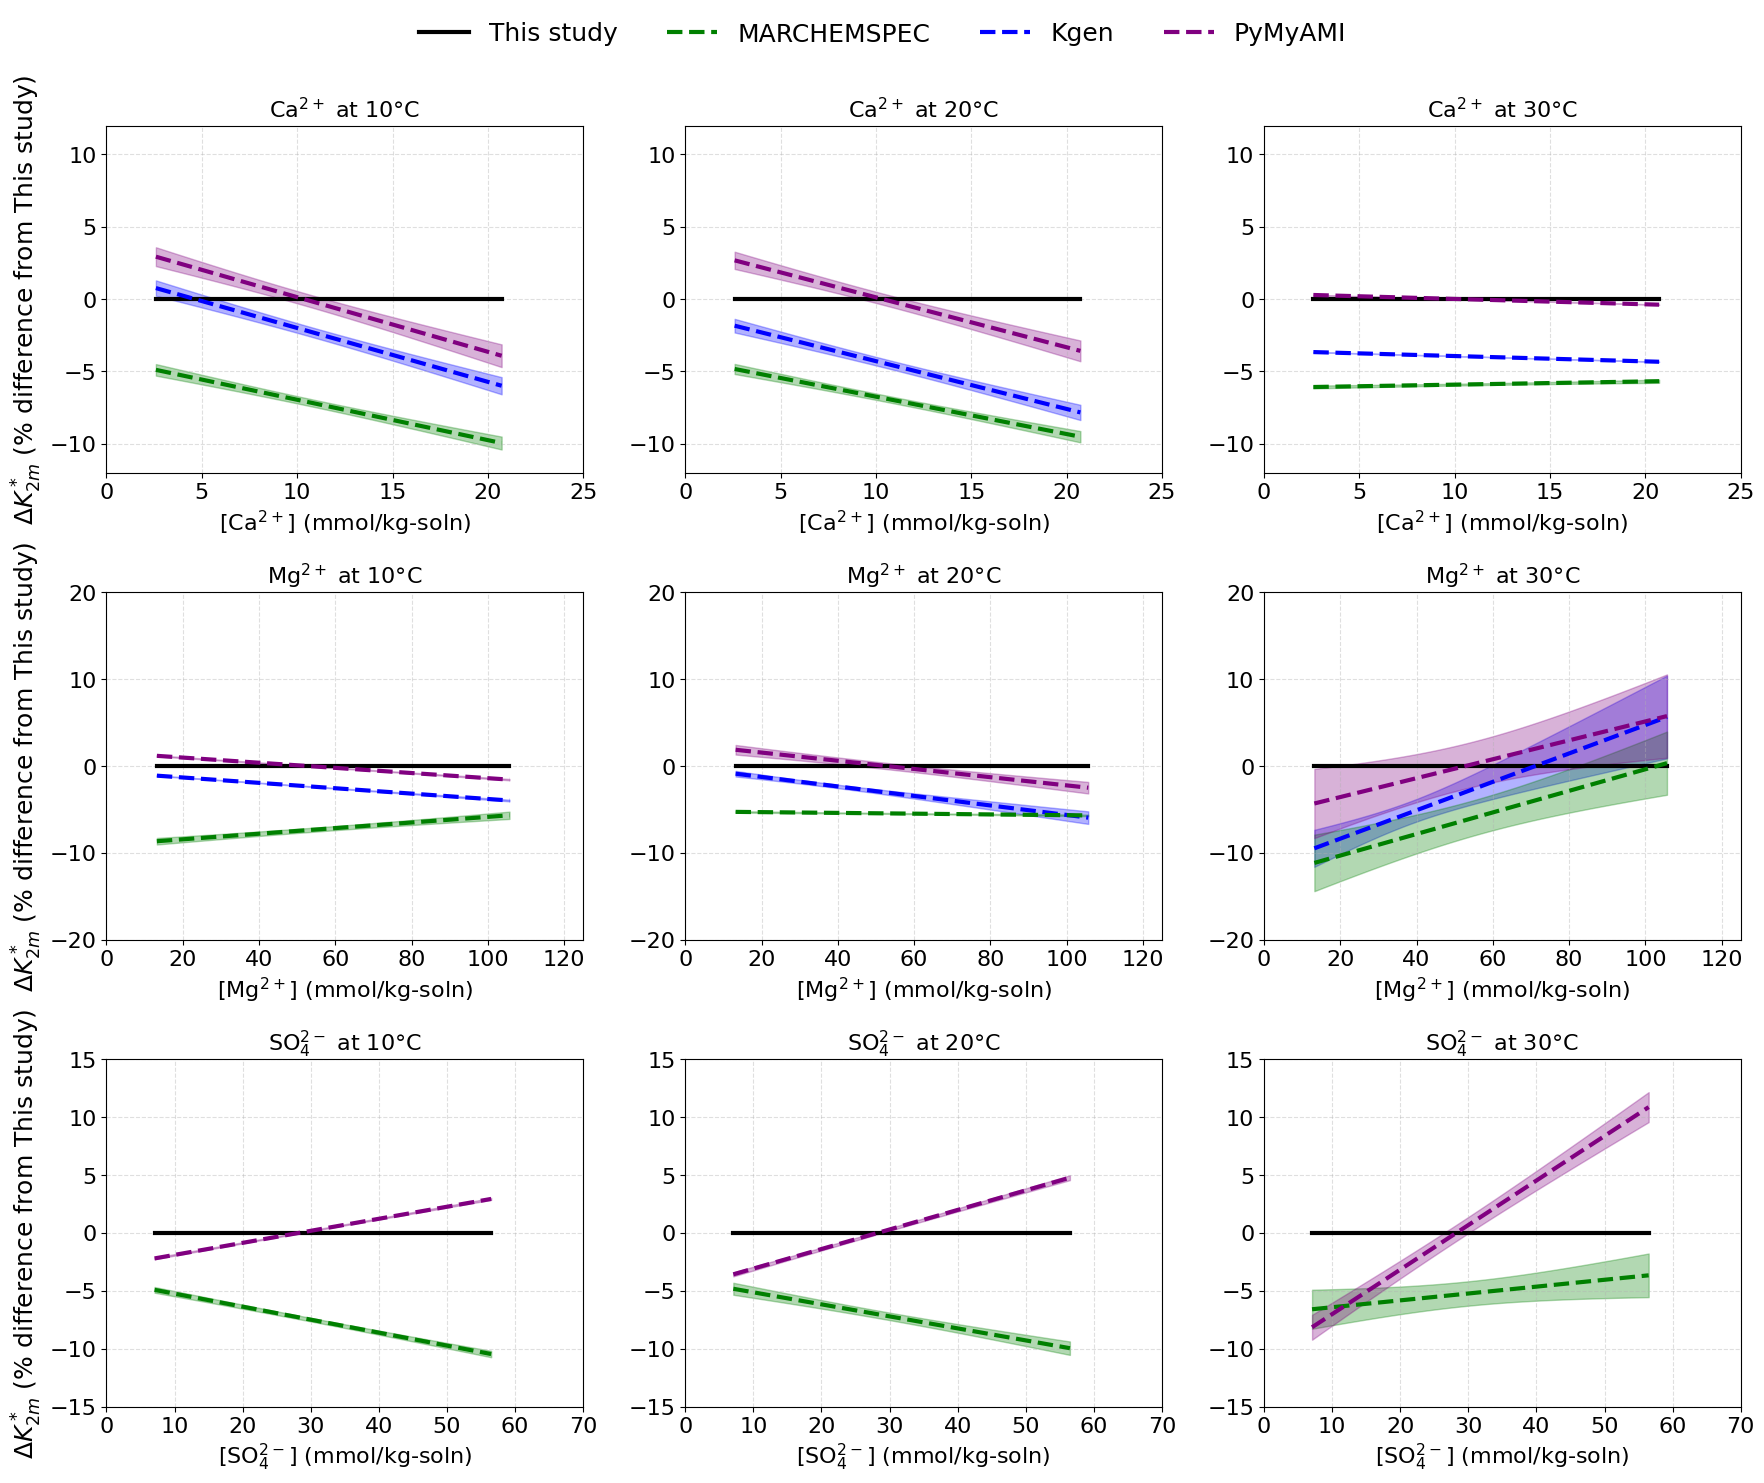

In [50]:
# Supplementary model-comparison analysis
#
# Load the non-standard seawater model data and calculate/plot relative
# differences between model formulations.

# ============================================================
# Load data
# ============================================================

model_comparison_data = pd.read_excel(
    DATA_WORKBOOK,
    sheet_name="Model_Data"
)

# ============================================================
# Ions and temperatures
# ============================================================

ions = ['Ca', 'Mg', 'SO4']

temperatures = sorted(
    model_comparison_data['T_C'].dropna().unique()
)

# ============================================================
# Marker + color maps
# ============================================================

marker_map = {
    'MARCHEMSPEC': 's',
    'Kgen': '^',
    'PyMyAMI': 'd'
}

color_map = {
    'MARCHEMSPEC': 'green',
    'Kgen': 'blue',
    'PyMyAMI': 'purple'
}

# ============================================================
# Axis limits
# ============================================================

xlim_map = {
    'Ca': (0, 25),
    'Mg': (0, 125),
    'SO4': (0, 70)
}

ylim_map = {
    'Ca': (-12, 12),
    'Mg': (-20, 20),
    'SO4': (-15, 15)
}

# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(18, 15),
    sharey=False
)

axes = axes.flatten()

# ============================================================
# Loop through ion × temperature
# ============================================================

for i, (ion, T) in enumerate(
    [(ion, T) for ion in ions for T in temperatures]
):

    ax = axes[i]

    # --------------------------------------------------------
    # Select ion
    # --------------------------------------------------------

    ion_data = model_comparison_data[
        model_comparison_data['Ion'].str.contains(
            ion,
            case=False,
            na=False
        )
    ].copy()

    # --------------------------------------------------------
    # Richardson data
    # --------------------------------------------------------

    rich = ion_data[
        ion_data['Formulation'] == 'Richardson'
    ].copy()

    # --------------------------------------------------------
    # Other formulations
    # --------------------------------------------------------

    others = ion_data[
        ion_data['Formulation'] != 'Richardson'
    ].copy()

    # Kgen is not available for SO4
    if ion == 'SO4':
        others = others[
            others['Formulation'] != 'Kgen'
        ]

    # ========================================================
    # 1. Richardson temperature-dependent regression
    #
    # Absolute K2 = 10^(-pK2)
    #
    # K_Richardson(C,T) = a + b*C
    # ========================================================

    rich_T = rich[
        (rich['T_C'] == T)
        & rich['Conc'].notna()
        & rich['pK2'].notna()
    ].copy()

    if rich_T.empty:
        continue

    X_rich = rich_T[
        'Conc'
    ].values.reshape(-1, 1)

    K_rich = (
        10 ** (
            -rich_T['pK2'].values
        )
    )

    # Fit Richardson absolute K2 regression
    reg_rich = LinearRegression().fit(
        X_rich,
        K_rich
    )

    # --------------------------------------------------------
    # Concentration range for Richardson regression
    # --------------------------------------------------------

    x_fit = np.linspace(
        X_rich.min(),
        X_rich.max(),
        100
    )

    # Richardson predicted K2
    K_rich_fit = reg_rich.predict(
        x_fit.reshape(-1, 1)
    )

    # ========================================================
    # 2. Richardson standard concentration
    # ========================================================

    std_rich = rich_T[
        np.isclose(
            rich_T['ConcMultiplier'],
            1.0
        )
    ]

    if std_rich.empty:
        raise ValueError(
            f"No Richardson standard concentration "
            f"found for {ion} at {T}°C."
        )

    conc_std = std_rich[
        'Conc'
    ].mean()

    # Richardson absolute K2 at standard composition
    K_rich_std = reg_rich.predict(
        np.array([[conc_std]])
    )[0]

    # ========================================================
    # 3. Richardson reference line
    #
    # Richardson is the reference.
    #
    # Therefore:
    #
    # ΔK_Richardson = 0%
    #
    # at every concentration.
    # ========================================================

    rich_percent_fit = np.zeros_like(
        x_fit
    )

    ax.plot(
        x_fit,
        rich_percent_fit,
        color='black',
        linewidth=3,
        label='This study'
    )

    # ========================================================
    # 4. Other formulations
    # ========================================================

    for name, df_form in others.groupby(
        'Formulation'
    ):

        df_T = df_form[
            (df_form['T_C'] == T)
            & df_form['Conc'].notna()
        ].copy()

        if df_T.empty:
            continue

        # ====================================================
        # MARCHEMSPEC / Kgen
        #
        # These provide absolute K2.
        #
        # First calculate their absolute K2:
        #
        # K_model = 10^(-pK2)
        #
        # Then calculate Richardson K2 at exactly the same
        # concentration:
        #
        # K_Rich(C,T)
        #
        # Finally:
        #
        # ΔK (%) =
        #
        # 100 * [1 - K_model / K_Rich]
        # ====================================================

        if name in [
            'Kgen',
            'MARCHEMSPEC'
        ]:

            df_T = df_T[
                df_T['pK2'].notna()
            ].copy()

            if df_T.empty:
                continue

            x_other = df_T[
                'Conc'
            ].values

            K2_other = (
                10 ** (
                    -df_T['pK2'].values
                )
            )

            valid = (
                np.isfinite(x_other)
                & np.isfinite(K2_other)
            )

            x_other = x_other[valid]
            K2_other = K2_other[valid]

            if len(x_other) == 0:
                continue

            # ------------------------------------------------
            # Richardson K2 at the model concentrations
            # ------------------------------------------------

            K_richardson_at_other = (
                reg_rich.predict(
                    x_other.reshape(-1, 1)
                )
            )

            # ------------------------------------------------
            # Relative difference from Richardson
            # ------------------------------------------------

            y_other = (
                100
                * (

                    (
                        K2_other
                        / K_richardson_at_other
                    )- 1
                )
            )

        # ====================================================
        # PyMyAMI
        #
        # PyMyAMI provides K2_ratio:
        #
        # K_PM(C,T) / K_PM,std(T)
        #
        # Richardson provides absolute K2, so calculate:
        #
        # K_Rich(C,T) / K_Rich,std(T)
        #
        # Then compare the two normalized responses:
        #
        # ΔK (%) =
        #
        # 100 * [
        #
        #     (
        #       K_PM_ratio
        #       /
        #       K_Rich_ratio
        #     ) -1
        # ]
        #
        # At standard:
        #
        # K_PM_ratio  = 1
        # K_Rich_ratio = 1
        #
        # Therefore:
        #
        # ΔK = 0%
        # ====================================================

        elif name == 'PyMyAMI':

            df_T = df_T[
                df_T['K2_ratio'].notna()
            ].copy()

            if df_T.empty:
                continue

            x_other = df_T[
                'Conc'
            ].values

            K_pymyami_ratio = df_T[
                'K2_ratio'
            ].values.astype(float)

            valid = (
                np.isfinite(x_other)
                & np.isfinite(
                    K_pymyami_ratio
                )
            )

            x_other = x_other[valid]

            K_pymyami_ratio = (
                K_pymyami_ratio[valid]
            )

            if len(x_other) == 0:
                continue

            # ------------------------------------------------
            # Richardson absolute K2 at PyMyAMI concentrations
            # ------------------------------------------------

            K_richardson_at_other = (
                reg_rich.predict(
                    x_other.reshape(-1, 1)
                )
            )

            # ------------------------------------------------
            # Richardson normalized response
            # ------------------------------------------------

            K_richardson_ratio = (
                K_richardson_at_other
                / K_rich_std
            )

            # ------------------------------------------------
            # Ratio divided by ratio
            # ------------------------------------------------

            y_other = (
                100
                * (

                    (
                        K_pymyami_ratio
                        / K_richardson_ratio
                    ) - 1
                )
            )

        else:
            continue

        # ====================================================
        # Plot model points
        # ====================================================

        c = color_map.get(
            name,
            'C0'
        )

        ax.scatter(
            x_other,
            y_other,
            marker=marker_map.get(
                name,
                'o'
            ),
            color=c,
            s=0,
            zorder=5
        )

        # ====================================================
        # Regression through model relative differences
        # ====================================================

        if len(x_other) <= 2:
            continue

        # ----------------------------------------------------
        # PyMyAMI
        #
        # Keep standard composition exactly at 0% by fitting
        # the response as a function of concentration relative
        # to the standard concentration.
        # ----------------------------------------------------

        if name == 'PyMyAMI':

            std_PM = df_T[
                np.isclose(
                    df_T['ConcMultiplier'],
                    1.0
                )
            ]

            if std_PM.empty:
                raise ValueError(
                    f"No PyMyAMI standard concentration "
                    f"found for {ion} at {T}°C."
                )

            C_std = std_PM[
                'Conc'
            ].iloc[0]

            X_centered = (
                x_other
                - C_std
            ).reshape(-1, 1)

            # No intercept:
            # guarantees 0% at standard composition.
            reg_other = LinearRegression(
                fit_intercept=False
            ).fit(
                X_centered,
                y_other
            )

            x_fit_centered = (
                x_fit
                - C_std
            ).reshape(-1, 1)

            y_other_fit = (
                reg_other.predict(
                    x_fit_centered
                )
            )

            # ------------------------------------------------
            # Confidence interval
            # ------------------------------------------------

            y_pred = reg_other.predict(
                X_centered
            )

            residuals = (
                y_other
                - y_pred
            )

            dof_other = (
                len(x_other)
                - 1
            )

            denominator_other = np.sum(
                X_centered.flatten() ** 2
            )

            if (
                dof_other > 0
                and denominator_other > 0
            ):

                s_err_other = np.sqrt(
                    np.sum(
                        residuals ** 2
                    )
                    / dof_other
                )

                t_val_other = stats.t.ppf(
                    0.975,
                    dof_other
                )

                conf_other = (
                    t_val_other
                    * s_err_other
                    * np.sqrt(
                        1 / len(x_other)
                        + (
                            x_fit
                            - C_std
                        ) ** 2
                        / denominator_other
                    )
                )

                ax.fill_between(
                    x_fit,
                    y_other_fit
                    - conf_other,
                    y_other_fit
                    + conf_other,
                    color=c,
                    alpha=0.3
                )

        # ----------------------------------------------------
        # MARCHEMSPEC / Kgen
        #
        # Ordinary regression of relative difference.
        # ----------------------------------------------------

        else:

            X_other = x_other.reshape(
                -1,
                1
            )

            reg_other = LinearRegression().fit(
                X_other,
                y_other
            )

            y_other_fit = (
                reg_other.predict(
                    x_fit.reshape(-1, 1)
                )
            )

            # ------------------------------------------------
            # Confidence interval
            # ------------------------------------------------

            y_pred = reg_other.predict(
                X_other
            )

            residuals = (
                y_other
                - y_pred
            )

            dof_other = (
                len(x_other)
                - 2
            )

            x_mean_other = np.mean(
                x_other
            )

            denominator_other = np.sum(
                (
                    x_other
                    - x_mean_other
                ) ** 2
            )

            if (
                dof_other > 0
                and denominator_other > 0
            ):

                s_err_other = np.sqrt(
                    np.sum(
                        residuals ** 2
                    )
                    / dof_other
                )

                t_val_other = stats.t.ppf(
                    0.975,
                    dof_other
                )

                conf_other = (
                    t_val_other
                    * s_err_other
                    * np.sqrt(
                        1 / len(x_other)
                        + (
                            x_fit
                            - x_mean_other
                        ) ** 2
                        / denominator_other
                    )
                )

                ax.fill_between(
                    x_fit,
                    y_other_fit
                    - conf_other,
                    y_other_fit
                    + conf_other,
                    color=c,
                    alpha=0.3
                )

        # ====================================================
        # PRINT ΔK RANGE ACROSS CONCENTRATION
        # ====================================================

        delta_k_min = np.min(y_other_fit)
        delta_k_max = np.max(y_other_fit)

        print(
            f"{ion:>3} | "
            f"{T:>4.0f}°C | "
            f"{name:<12} | "
            f"ΔK range = "
            f"{delta_k_min: .3f}% to "
            f"{delta_k_max: .3f}%"
        )

        # ====================================================
        # PRINT AVERAGE ΔK ACROSS K2 CONCENTRATIONS
        # ====================================================

        delta_k_average = np.mean(y_other)

        print(
            f"{ion:>3} | "
            f"{T:>4.0f}°C | "
            f"{name:<12} | "
            f"Average ΔK = "
            f"{delta_k_average: .3f}%"
        )

        # ====================================================
        # Plot model regression
        # ====================================================

        ax.plot(
            x_fit,
            y_other_fit,
            linestyle='--',
            color=c,
            linewidth=3,
            label=name
        )

    # ========================================================
    # Axis limits
    # ========================================================

    ax.set_xlim(
        xlim_map[ion]
    )

    ax.set_ylim(
        ylim_map[ion]
    )

    # ========================================================
    # Axis labels
    # ========================================================

    x_label_map = {
        'Ca':
            r'[Ca$^{2+}$] (mmol/kg-soln)',
        'Mg':
            r'[Mg$^{2+}$] (mmol/kg-soln)',
        'SO4':
            r'[SO$_4^{2-}$] (mmol/kg-soln)'
    }

    ax.set_xlabel(
        x_label_map[ion],
        fontsize=16
    )

    # ========================================================
    # Titles
    # ========================================================

    x_title_map = {
        'Ca':
            r'Ca$^{2+}$',
        'Mg':
            r'Mg$^{2+}$',
        'SO4':
            r'SO$_4^{2-}$'
    }

    ax.set_title(
        x_title_map[ion]
        + f' at {T}°C',
        fontsize=16
    )

    # ========================================================
    # Grid + ticks
    # ========================================================

    ax.grid(
        True,
        linestyle='--',
        alpha=0.4
    )

    ax.tick_params(
        labelsize=16
    )

# ============================================================
# Y-axis labels
# ============================================================

for row in range(3):

    axes[
        row * 3
    ].set_ylabel(
        r'$\Delta K^*_{2m}$ (% difference from This study)',
        fontsize=18
    )

# ============================================================
# Legend
# ============================================================

handles = [
    Line2D(
        [0],
        [0],
        color='black',
        lw=3,
        label='This study'
    )
]

for formulation, color in color_map.items():

    handles.append(
        Line2D(
            [0],
            [0],
            color=color,
            lw=3,
            linestyle='--',
            marker=marker_map[formulation],
            markersize=0,
            label=formulation
        )
    )

fig.legend(
    handles,
    [
        handle.get_label()
        for handle in handles
    ],
    loc='upper center',
    ncol=4,
    fontsize=18,
    frameon=False
)

# ============================================================
# Layout
# ============================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_7.png', dpi=600, bbox_inches='tight')
plt.show()


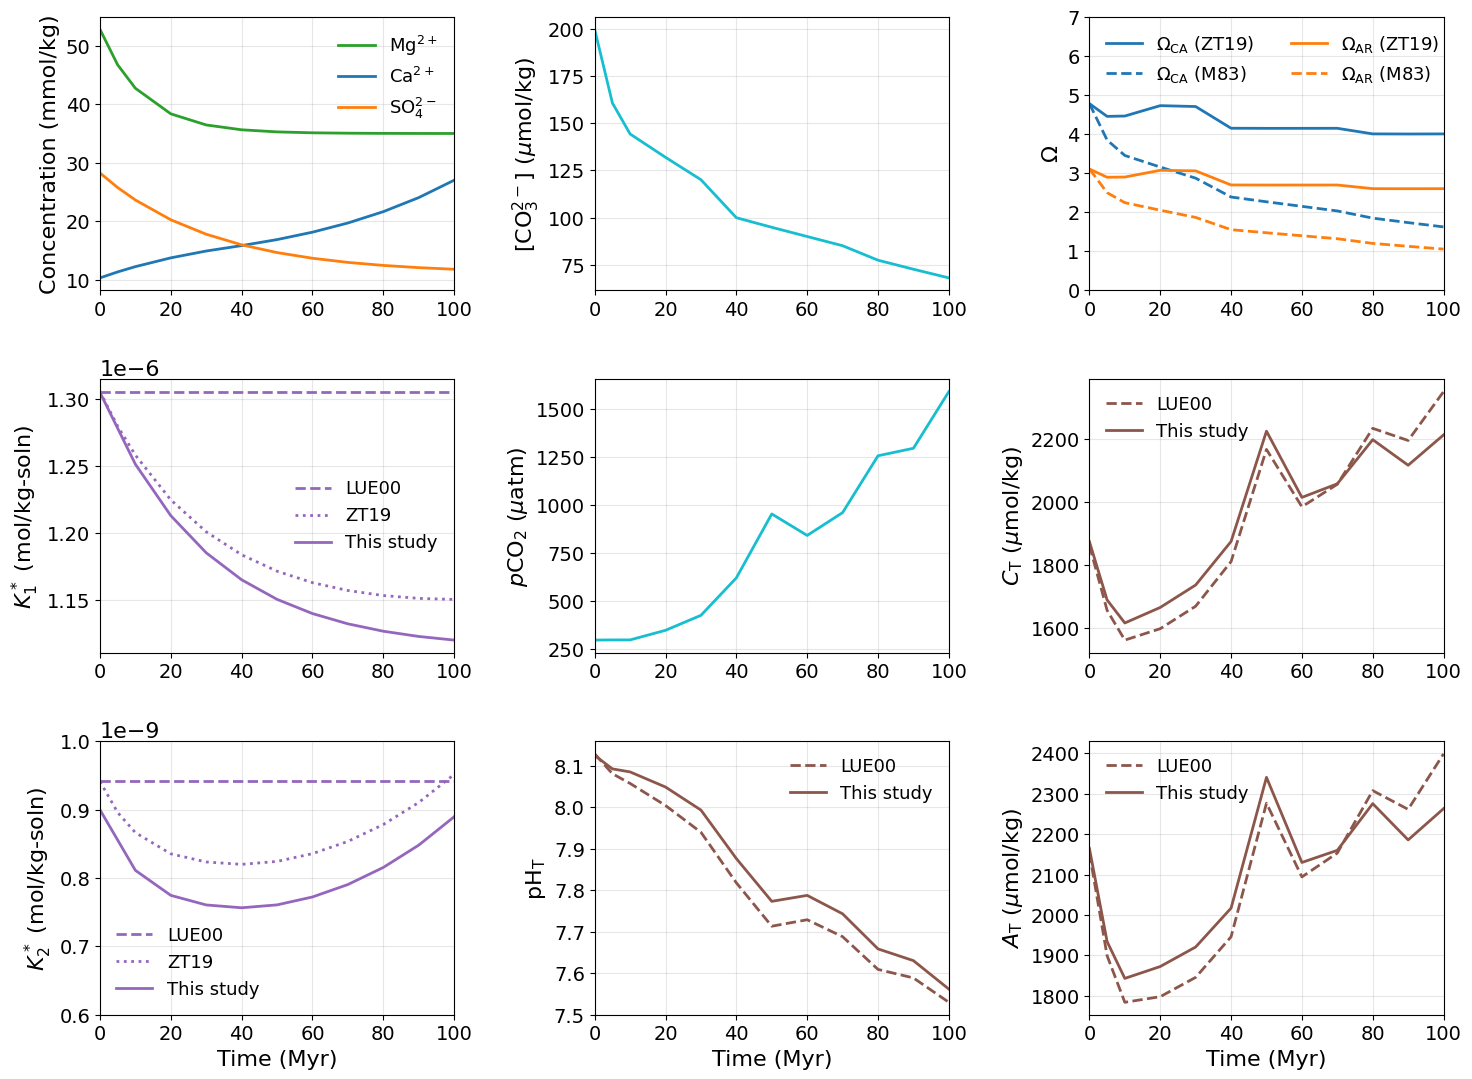

In [52]:
# ===============================
#error propagation for K1 and K2 using Appendix 2

stdk1 = 1.3055E-06
stdk2 = 9.4135E-10

# ===============================
# ZT19 Eq. (2)
# ===============================
def zt19_eq2(xp, xpp, t, t1, tau):
    """Zeebe & Tyrrell (2019) Eq. (2)"""
    return (xp - xpp) * np.exp(-(t - t1) / tau) + xpp


# ===============================
# Time arrays (Ma)
# ===============================
t = np.arange(0, 101, 1)
t037 = np.arange(0, 37, 1)
t37100 = np.arange(37, 101, 1)

# ===============================
# Major ions
# ===============================
Mg = zt19_eq2(xp=52.82, xpp=35, t=t, t1=0, tau=12)
SO4 = zt19_eq2(xp=28.24, xpp=11, t=t, t1=0, tau=32)

Ca_037 = zt19_eq2(xp=10.280, xpp=19.0, t=t037, t1=0, tau=40)
Ca_37100 = zt19_eq2(xp=15.542, xpp=11.478, t=t37100, t1=37, tau=-47.011)

Ca = np.empty_like(t, dtype=float)
Ca[0:37] = Ca_037
Ca[37:101] = Ca_37100

# ===============================
# Interpolated K values
# ===============================
MgK1_interp = (0.027e-8) * Mg + 1.295e-6
CaK1_interp = (0.012e-8) * Ca + 1.296e-6
SO4K1_interp = (1.1062e-8) * SO4 + 0.997e-6

MgK2_interp = (0.09e-10) * Mg + 0.434e-9
CaK2_interp = (0.145e-10) * Ca + 0.788e-9
SO4K2_interp = (0.056e-10) * SO4 + 0.778e-9

# ===============================
# DataFrames
# ===============================
interK_mg_df = pd.DataFrame(columns=[
    'Age_Ma', 'MgK1_interp', 'pct_diff_K1_mg',
    'MgK2_interp', 'pct_diff_K2_mg'
])

interK_ca_df = pd.DataFrame(columns=[
    'Age_Ma', 'CaK1_interp', 'pct_diff_K1_ca',
    'CaK2_interp', 'pct_diff_K2_ca'
])

interK_so4_df = pd.DataFrame(columns=[
    'Age_Ma', 'SO4K1_interp', 'pct_diff_K1_so4',
    'SO4K2_interp', 'pct_diff_K2_so4'
])

# ===============================
# Loop (every 5 Ma)
# ===============================
for ti in range(0, 101, 10):

    # ---- K1 percent differences ----
    pct_diff_K1_mg = 100 * (MgK1_interp[ti] - stdk1) / stdk1
    pct_diff_K1_ca = 100 * (CaK1_interp[ti] - stdk1) / stdk1
    pct_diff_K1_so4 = 100 * (SO4K1_interp[ti] - stdk1) / stdk1

    # ---- K2 percent differences ----
    pct_diff_K2_mg = 100 * (MgK2_interp[ti] - stdk2) / stdk2
    pct_diff_K2_ca = 100 * (CaK2_interp[ti] - stdk2) / stdk2
    pct_diff_K2_so4 = 100 * (SO4K2_interp[ti] - stdk2) / stdk2

    # ---- Append ----
    interK_mg_df.loc[len(interK_mg_df)] = [
        ti,
        MgK1_interp[ti], pct_diff_K1_mg,
        MgK2_interp[ti], pct_diff_K2_mg
    ]

    interK_ca_df.loc[len(interK_ca_df)] = [
        ti,
        CaK1_interp[ti], pct_diff_K1_ca,
        CaK2_interp[ti], pct_diff_K2_ca
    ]

    interK_so4_df.loc[len(interK_so4_df)] = [
        ti,
        SO4K1_interp[ti], pct_diff_K1_so4,
        SO4K2_interp[ti], pct_diff_K2_so4
    ]


# ===============================
# Combine Mg + Ca + Sulfate
# (K1 and K2 together)
# ===============================
interK_total_df = (
    interK_mg_df[['Age_Ma', 'pct_diff_K1_mg', 'pct_diff_K2_mg']]
    .merge(
        interK_ca_df[['Age_Ma', 'pct_diff_K1_ca', 'pct_diff_K2_ca']],
        on='Age_Ma'
    )
    .merge(
        interK_so4_df[['Age_Ma', 'pct_diff_K1_so4', 'pct_diff_K2_so4']],
        on='Age_Ma'
    )
)

# ===============================
# Additive sums (ZT19 assumption)
# ===============================
interK_total_df['pct_diff_K1_total'] = (
    interK_total_df['pct_diff_K1_mg']
    + interK_total_df['pct_diff_K1_ca']
    + interK_total_df['pct_diff_K1_so4']
)

interK_total_df['pct_diff_K2_total'] = (
    interK_total_df['pct_diff_K2_mg']
    + interK_total_df['pct_diff_K2_ca']
    + interK_total_df['pct_diff_K2_so4']
)

# print(interK_total_df)
# # Save combined percent differences as CSV
# interK_total_df.to_csv('interK_total_percent_diff.csv', index=False)
# print("Saved as interK_total_percent_diff.csv")


# ============================================================
# 9-PANEL GEOCARB / CARBONATE CHEMISTRY FIGURE
#
# Zeebe & Tyrrell (2019) major-ion corrections
# + Lueker et al. (2000)
# + This Work K1*/K2*
#
# ROW 1:
#   Mg/Ca/SO4     CO3 GEOCARB       Omega calcite/aragonite
#
# ROW 2:
#   K1*            pCO2 GEOCARB      DIC
#
# ROW 3:
#   K2*            pHT               TA
#
# Age = 0–100 Ma, left -> right
# ============================================================


# ============================================================
# GEOCARB INPUT DATA
#
# Directly from Z&T 2019 GEOCARB scenario
# ============================================================

ages = np.array([
    0, 5, 10, 20, 30, 40,
    50, 60, 70, 80, 90, 100
], dtype=float)


co3 = np.array([
    200.0,
    160.9,
    144.4,
    132.0,
    120.1,
    99.9,
    94.8,
    89.9,
    85.0,
    77.3,
    72.5,
    67.9
])


pCO2 = np.array([
    296,
    297,
    297,
    347,
    425,
    620,
    953,
    841,
    960,
    1256,
    1295,
    1590
])


# GEOCARB DIC and TA are supplied in mmol/kg
DIC_GEOCARB = np.array([
    2.083,
    1.845,
    1.724,
    1.726,
    1.816,
    1.915,
    2.182,
    2.012,
    2.077,
    2.206,
    2.076,
    2.176
]) * 1000


TA_GEOCARB = np.array([
    2.363,
    2.083,
    1.946,
    1.932,
    1.999,
    2.056,
    2.298,
    2.127,
    2.178,
    2.282,
    2.145,
    2.225
]) * 1000


pH_GEOCARB = np.array([
    8.17,
    8.13,
    8.11,
    8.06,
    8.00,
    7.88,
    7.76,
    7.78,
    7.74,
    7.65,
    7.62,
    7.55
])


# ============================================================
# 3. Z&T 2019 MAJOR ION RECONSTRUCTION
#
# Eq. 2:
#
# x(t) = (x0 - x00) * exp[-(t-t1)/s] + x00
#
# Z&T use a piecewise Ca fit with a breakpoint at 37 Ma.
# ============================================================


def exponential_fit(t, x0, x00, t1, s):
    return (
        (x0 - x00)
        * np.exp(-(t - t1) / s)
        + x00
    )


# ------------------------------------------------------------
# Calcium
# ------------------------------------------------------------

# 0–37 Ma
Ca_0_37 = exponential_fit(
    ages,
    x0=10.280,
    x00=19.000,
    t1=0,
    s=40.000
)


# 37–100 Ma
Ca_37_100 = exponential_fit(
    ages,
    x0=15.542,
    x00=11.478,
    t1=37,
    s=-47.011
)


Ca_ZT = np.where(
    ages <= 37,
    Ca_0_37,
    Ca_37_100
)


# ------------------------------------------------------------
# Magnesium
# ------------------------------------------------------------

Mg_ZT = exponential_fit(
    ages,
    x0=52.820,
    x00=35.000,
    t1=0,
    s=12.000
)


# ------------------------------------------------------------
# Sulfate
# ------------------------------------------------------------

SO4_ZT = exponential_fit(
    ages,
    x0=28.240,
    x00=11.000,
    t1=0,
    s=32.000
)


# ============================================================
# 4. MODERN REFERENCE VALUES
# ============================================================

Ca0 = 10.280
Mg0 = 52.820
SO40 = 28.240


# ============================================================
# 5. Z&T 2019 SENSITIVITY COEFFICIENTS
#
# Values from Table 2.
#
# Table reports sij × 10^3.
# Therefore:
#
# K1:
#   Ca   0.005
#   Mg   0.017
#   SO4  0.208
#
# K2:
#   Ca   0.157
#   Mg   0.420
#   SO4  0.176
#
# Ksp:
#   Ca   0.185
#   Mg   0.518
#   SO4  0.106
#
# ============================================================


# K1*
s_K1_Ca = 0.005
s_K1_Mg = 0.017
s_K1_SO4 = 0.208


# K2*
s_K2_Ca = 0.157
s_K2_Mg = 0.420
s_K2_SO4 = 0.176


# Ksp
s_Ksp_Ca = 0.185
s_Ksp_Mg = 0.518
s_Ksp_SO4 = 0.106


# ============================================================
# 6. Z&T K* CORRECTIONS
#
# Z&T Eq. 10:
#
# Ki*/Ki,m* =
# 1 + sum[sij * (xj/xj,m - 1)]
# ============================================================


K1_ratio_ZT = (
    1
    + s_K1_Ca * (Ca_ZT / Ca0 - 1)
    + s_K1_Mg * (Mg_ZT / Mg0 - 1)
    + s_K1_SO4 * (SO4_ZT / SO40 - 1)
)


K2_ratio_ZT = (
    1
    + s_K2_Ca * (Ca_ZT / Ca0 - 1)
    + s_K2_Mg * (Mg_ZT / Mg0 - 1)
    + s_K2_SO4 * (SO4_ZT / SO40 - 1)
)


Ksp_ratio_ZT = (
    1
    + s_Ksp_Ca * (Ca_ZT / Ca0 - 1)
    + s_Ksp_Mg * (Mg_ZT / Mg0 - 1)
    + s_Ksp_SO4 * (SO4_ZT / SO40 - 1)
)


# ============================================================
# 7. LUEKER CONSTANTS
#
# These are  values at 20 C, S = 35.
# ============================================================

K1_Lueker = 1.3055E-06
K2_Lueker = 9.4135E-10


# Z&T K1/K2
K1_ZT = K1_Lueker * K1_ratio_ZT
K2_ZT = K2_Lueker * K2_ratio_ZT


# ============================================================
# 8.  rich K1/K2
# ============================================================

ages_thiswork = (
    interK_total_df['Age_Ma']
    .values
)


K1_thiswork = (
    interK_total_df['pct_diff_K1_total'].values
    * K1_Lueker / 100
    + K1_Lueker
)


K2_thiswork = (
    interK_total_df['pct_diff_K2_total'].values
    * K2_Lueker / 100
    + K2_Lueker
)


# Interpolate rich work onto the GEOCARB ages
K1_thiswork = np.interp(
    ages,
    ages_thiswork,
    K1_thiswork
)


K2_thiswork = np.interp(
    ages,
    ages_thiswork,
    K2_thiswork
)


# ============================================================
# 9. Ksp
#
# Z&T non-standard Ksp
# ============================================================


#  supplied modern Z&T values
Ksp_calcite_mod = 4.3000351488246635e-07
Ksp_aragonite_mod = 6.616236648649715e-07


Ksp_calcite_ZT = (
    Ksp_calcite_mod
    * Ksp_ratio_ZT
)


Ksp_aragonite_ZT = (
    Ksp_aragonite_mod
    * Ksp_ratio_ZT
)


# ============================================================
# 10. CARBONATE SYSTEM CONDITIONS
# ============================================================

T = 20.0
S = 35.0


# ============================================================
# 11. PYCO2SYS CALCULATIONS
# ============================================================

results_lueker = []
results_ZT = []
results_thiswork = []
results_Mucci = []


for i in range(len(ages)):

    # --------------------------------------------------------
    # LUEKER
    # --------------------------------------------------------

    results_lueker.append(
        pyco2.sys(
            par1=pCO2[i],
            par1_type=4,

            par2=co3[i],
            par2_type=6,

            salinity=S,
            temperature=T,

            opt_k_carbonic=10
        )
    )


    # --------------------------------------------------------
    # Z&T 2019
    #
    # Non-standard K1*, K2*, Ksp
    # --------------------------------------------------------

    results_ZT.append(
        pyco2.sys(
            par1=pCO2[i],
            par1_type=4,

            par2=co3[i],
            par2_type=6,

            salinity=S,
            temperature=T,

            k_carbonic_1=K1_ZT[i],
            k_carbonic_2=K2_ZT[i],

            k_calcite=Ksp_calcite_ZT[i],
            k_aragonite=Ksp_aragonite_ZT[i],

            total_calcium=Ca_ZT[i] * 1000
        )
    )


    # --------------------------------------------------------
    # THIS WORK
    #
    #  K1*/K2*
    # plus Z&T non-standard Ksp
    # --------------------------------------------------------

    results_thiswork.append(
        pyco2.sys(
            par1=pCO2[i],
            par1_type=4,

            par2=co3[i],
            par2_type=6,

            salinity=S,
            temperature=T,

            k_carbonic_1=K1_thiswork[i],
            k_carbonic_2=K2_thiswork[i],

            k_calcite=Ksp_calcite_ZT[i],
            k_aragonite=Ksp_aragonite_ZT[i],

            total_calcium=Ca_ZT[i] * 1000
        )
    )


    # --------------------------------------------------------
    # MUCCI 1983
    #
    # Standard K1/K2 + standard Mucci Ksp
    # --------------------------------------------------------

    results_Mucci.append(
        pyco2.sys(
            par1=pCO2[i],
            par1_type=4,

            par2=co3[i],
            par2_type=6,

            salinity=S,
            temperature=T,

            opt_k_carbonic=10
        )
    )


# ============================================================
# 12. HELPER
# ============================================================

def get(results, key):

    return np.array([
        r[key]
        for r in results
    ])


# ============================================================
# 13. EXTRACT RESULTS
# ============================================================


# ---- Lueker ----

DIC_Lueker = get(
    results_lueker,
    'dic'
)

TA_Lueker = get(
    results_lueker,
    'alkalinity'
)

pH_Lueker = get(
    results_lueker,
    'pH'
)

Omega_calcite_Mucci = get(
    results_Mucci,
    'saturation_calcite'
)

Omega_aragonite_Mucci = get(
    results_Mucci,
    'saturation_aragonite'
)


# ---- Z&T ----

Omega_calcite_ZT = get(
    results_ZT,
    'saturation_calcite'
)

Omega_aragonite_ZT = get(
    results_ZT,
    'saturation_aragonite'
)


# ---- This Work ----

DIC_thiswork = get(
    results_thiswork,
    'dic'
)

TA_thiswork = get(
    results_thiswork,
    'alkalinity'
)

pH_thiswork = get(
    results_thiswork,
    'pH'
)


# ============================================================
# 14. CREATE 3 × 3 FIGURE
# ============================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 11)
)


lw = 2

# Larger text
fs = 16
tick_fs = 14
legend_fs = 13


# ============================================================
# PANEL A
# MAJOR IONS
#
# Reviewer:
# Blue / green / orange reserved for fluid-inclusion /
# major-ion data.
# ============================================================

ax = axes[0, 0]

ax.plot(
    ages,
    Mg_ZT,
    lw=lw,
    color='tab:green',
    label=r'Mg$^{2+}$'
)

ax.plot(
    ages,
    Ca_ZT,
    lw=lw,
    color='tab:blue',
    label=r'Ca$^{2+}$'
)

ax.plot(
    ages,
    SO4_ZT,
    lw=lw,
    color='tab:orange',
    label=r'SO$_4^{2-}$'
)

ax.set_ylabel(
    'Concentration (mmol/kg)',
    fontsize=fs
)

ax.legend(
    frameon=False,
    fontsize=legend_fs
)


# ============================================================
# PANEL B
# GEOCARB CO3
#
# CO3 / pCO2 = input parameters
# Same color, differentiated by line style.
# ============================================================

ax = axes[0, 1]

ax.plot(
    ages,
    co3,
    color='tab:cyan',
    linestyle='-',
    lw=lw,
    label=r'[CO$_3^{2-}$]'
)

ax.set_ylabel(
    r'[CO$_3^{2-}$] ($\mu$mol/kg)',
    fontsize=fs
)

# ax.legend(
#     frameon=False,
#     fontsize=legend_fs
# )


# ============================================================
# PANEL C
# SATURATION STATE
#
# Calcite vs aragonite = color
# Standard vs non-standard Ksp = line style
# ============================================================

ax = axes[0, 2]

# ------------------------------------------------------------
# CALCITE
# ------------------------------------------------------------

# Non-standard Ksp — Z&T 2019
ax.plot(
    ages,
    Omega_calcite_ZT,
    lw=lw,
    color='tab:blue',
    linestyle='-',
    label=r'$\Omega$$_{\mathrm{CA}}$ (ZT19)'
)

# Standard Ksp — Mucci 1983
ax.plot(
    ages,
    Omega_calcite_Mucci,
    lw=lw,
    color='tab:blue',
    linestyle='--',
    label=r'$\Omega$$_{\mathrm{CA}}$ (M83)'
)


# ------------------------------------------------------------
# ARAGONITE
# ------------------------------------------------------------

# Non-standard Ksp — Z&T 2019
ax.plot(
    ages,
    Omega_aragonite_ZT,
    lw=lw,
    color='tab:orange',
    linestyle='-',
    label=r'$\Omega$$_{\mathrm{AR}}$ (ZT19)'

)
# Standard Ksp — Mucci 1983
ax.plot(
    ages,
    Omega_aragonite_Mucci,
    lw=lw,
    color='tab:orange',
    linestyle='--',
    label=r'$\Omega$$_{\mathrm{AR}}$ (M83)'
)
ax.set_ylim(0,7)


ax.set_ylabel(
    r'$\Omega$',
    fontsize=fs
)

ax.legend(
    frameon=False,
    fontsize=legend_fs,
    loc='upper left',
    ncol=2
    
)


# ============================================================
# PANEL D
# K1*
#
# K1 / K2 = one color family
# Lueker / Z&T / This Work = line style
# ============================================================

ax = axes[1, 0]

ax.plot(
    ages,
    np.full_like(
        ages,
        K1_Lueker
    ),
    color='tab:purple',
    linestyle='--',
    lw=lw,
    label='LUE00'
)

ax.plot(
    ages,
    K1_ZT,
    color='tab:purple',
    linestyle=':',
    lw=lw,
    label='ZT19'
)

ax.plot(
    ages,
    K1_thiswork,
    color='tab:purple',
    linestyle='-',
    lw=lw,
    label='This study'
)

ax.set_ylabel(
    r'$K_1^*$ (mol/kg-soln)',
    fontsize=fs
)

ax.legend(
    frameon=False,
    fontsize=legend_fs
)


# ============================================================
# PANEL E
# GEOCARB pCO2
#
# CO3 / pCO2 = input parameters
# Same color, differentiated by line style.
# ============================================================

ax = axes[1, 1]

ax.plot(
    ages,
    pCO2,
    color='tab:cyan',
    linestyle='-',
    lw=lw,
    label=r'$\mathit{p}\mathrm{CO}_2$'
)

ax.set_ylabel(
    r'$\mathit{p}\mathrm{CO}_2$ ($\mu$atm)',
    fontsize=fs
)

# ax.legend(
#     frameon=False,
#     fontsize=legend_fs
# )


# ============================================================
# PANEL F
# DIC
#
# Calculation outputs
# Standard vs non-standard K* = line style
# ============================================================

ax = axes[1, 2]

ax.plot(
    ages,
    DIC_Lueker,
    color='tab:brown',
    linestyle='--',
    lw=lw,
    label=r'LUE00'
)

ax.plot(
    ages,
    DIC_thiswork,
    color='tab:brown',
    linestyle='-',
    lw=lw,
    label=r'This study'
)

ax.set_ylabel(
    r'$C_{\mathrm{T}}$ ($\mu$mol/kg)',
    fontsize=fs
)

ax.legend(
    frameon=False,
    fontsize=legend_fs
)


# ============================================================
# PANEL G
# K2*
#
# K1 / K2 = one color family
# Lueker / Z&T / This Work = line style
# ============================================================

ax = axes[2, 0]

ax.plot(
    ages,
    np.full_like(
        ages,
        K2_Lueker
    ),
    color='tab:purple',
    linestyle='--',
    lw=lw,
    label='LUE00'
)

ax.plot(
    ages,
    K2_ZT,
    color='tab:purple',
    linestyle=':',
    lw=lw,
    label='ZT19'
)

ax.plot(
    ages,
    K2_thiswork,
    color='tab:purple',
    linestyle='-',
    lw=lw,
    label='This study'
)

ax.set_ylabel(
    r'$K_2^*$ (mol/kg-soln)',
    fontsize=fs
)

ax.legend(
    frameon=False,
    fontsize=legend_fs
)
ax.set_ylim(6e-10,10e-10)

# ============================================================
# PANEL H
# pH
#
# Calculation outputs
# Standard vs non-standard K* = line style
# ============================================================

ax = axes[2, 1]

ax.plot(
    ages,
    pH_Lueker,
    color='tab:brown',
    linestyle='--',
    lw=lw,
    label=r'LUE00'
)

ax.plot(
    ages,
    pH_thiswork,
    color='tab:brown',
    linestyle='-',
    lw=lw,
    label=r'This study'
)

ax.set_ylabel(
    r'${\mathrm{pH}}_{\mathrm{T}}$ ',
    fontsize=fs
)

ax.legend(
    frameon=False,
    fontsize=legend_fs
)


# ============================================================
# PANEL I
# TOTAL ALKALINITY
#
# Calculation outputs
# Standard vs non-standard K* = line style
# ============================================================

ax = axes[2, 2]

ax.plot(
    ages,
    TA_Lueker,
    color='tab:brown',
    linestyle='--',
    lw=lw,
    label=r'LUE00'
)

ax.plot(
    ages,
    TA_thiswork,
    color='tab:brown',
    linestyle='-',
    lw=lw,
    label=r'This study'
)

ax.set_ylabel(
    r'$A_{\mathrm{T}}$ ($\mu$mol/kg)',
    fontsize=fs
)

ax.legend(
    frameon=False,
    fontsize=legend_fs
)


# ============================================================
# 15. COMMON FORMATTING
# ============================================================

for ax in axes.flat:

    ax.set_xlim(
        0,
        100
    )

    ax.set_xticks(
        [0, 20, 40, 60, 80, 100]
    )

    ax.tick_params(
        axis='both',
        labelsize=tick_fs
    )

    ax.grid(
        True,
        alpha=0.3
    )


# ============================================================
# X LABELS ONLY ON BOTTOM ROW
# ============================================================

for ax in axes[2, :]:

    ax.set_xlabel(
        'Time (Myr)',
        fontsize=fs
    )


# ============================================================
# 16. NO PANEL LABELS
# ============================================================
# Panel lettering (a–i) removed.


# ============================================================
# 17. SAVE
# ============================================================

plt.tight_layout(
    h_pad=1.8,
    w_pad=1.5
)


plt.savefig(
    FIGURE_OUTPUT_DIR / 'GEOCARB_9_panel_ZT2019_ThisWork.png',
    dpi=600,
    bbox_inches='tight'
)


plt.savefig(
    FIGURE_OUTPUT_DIR / 'GEOCARB_9_panel_ZT2019_ThisWork.pdf',
    bbox_inches='tight'
)


plt.show()


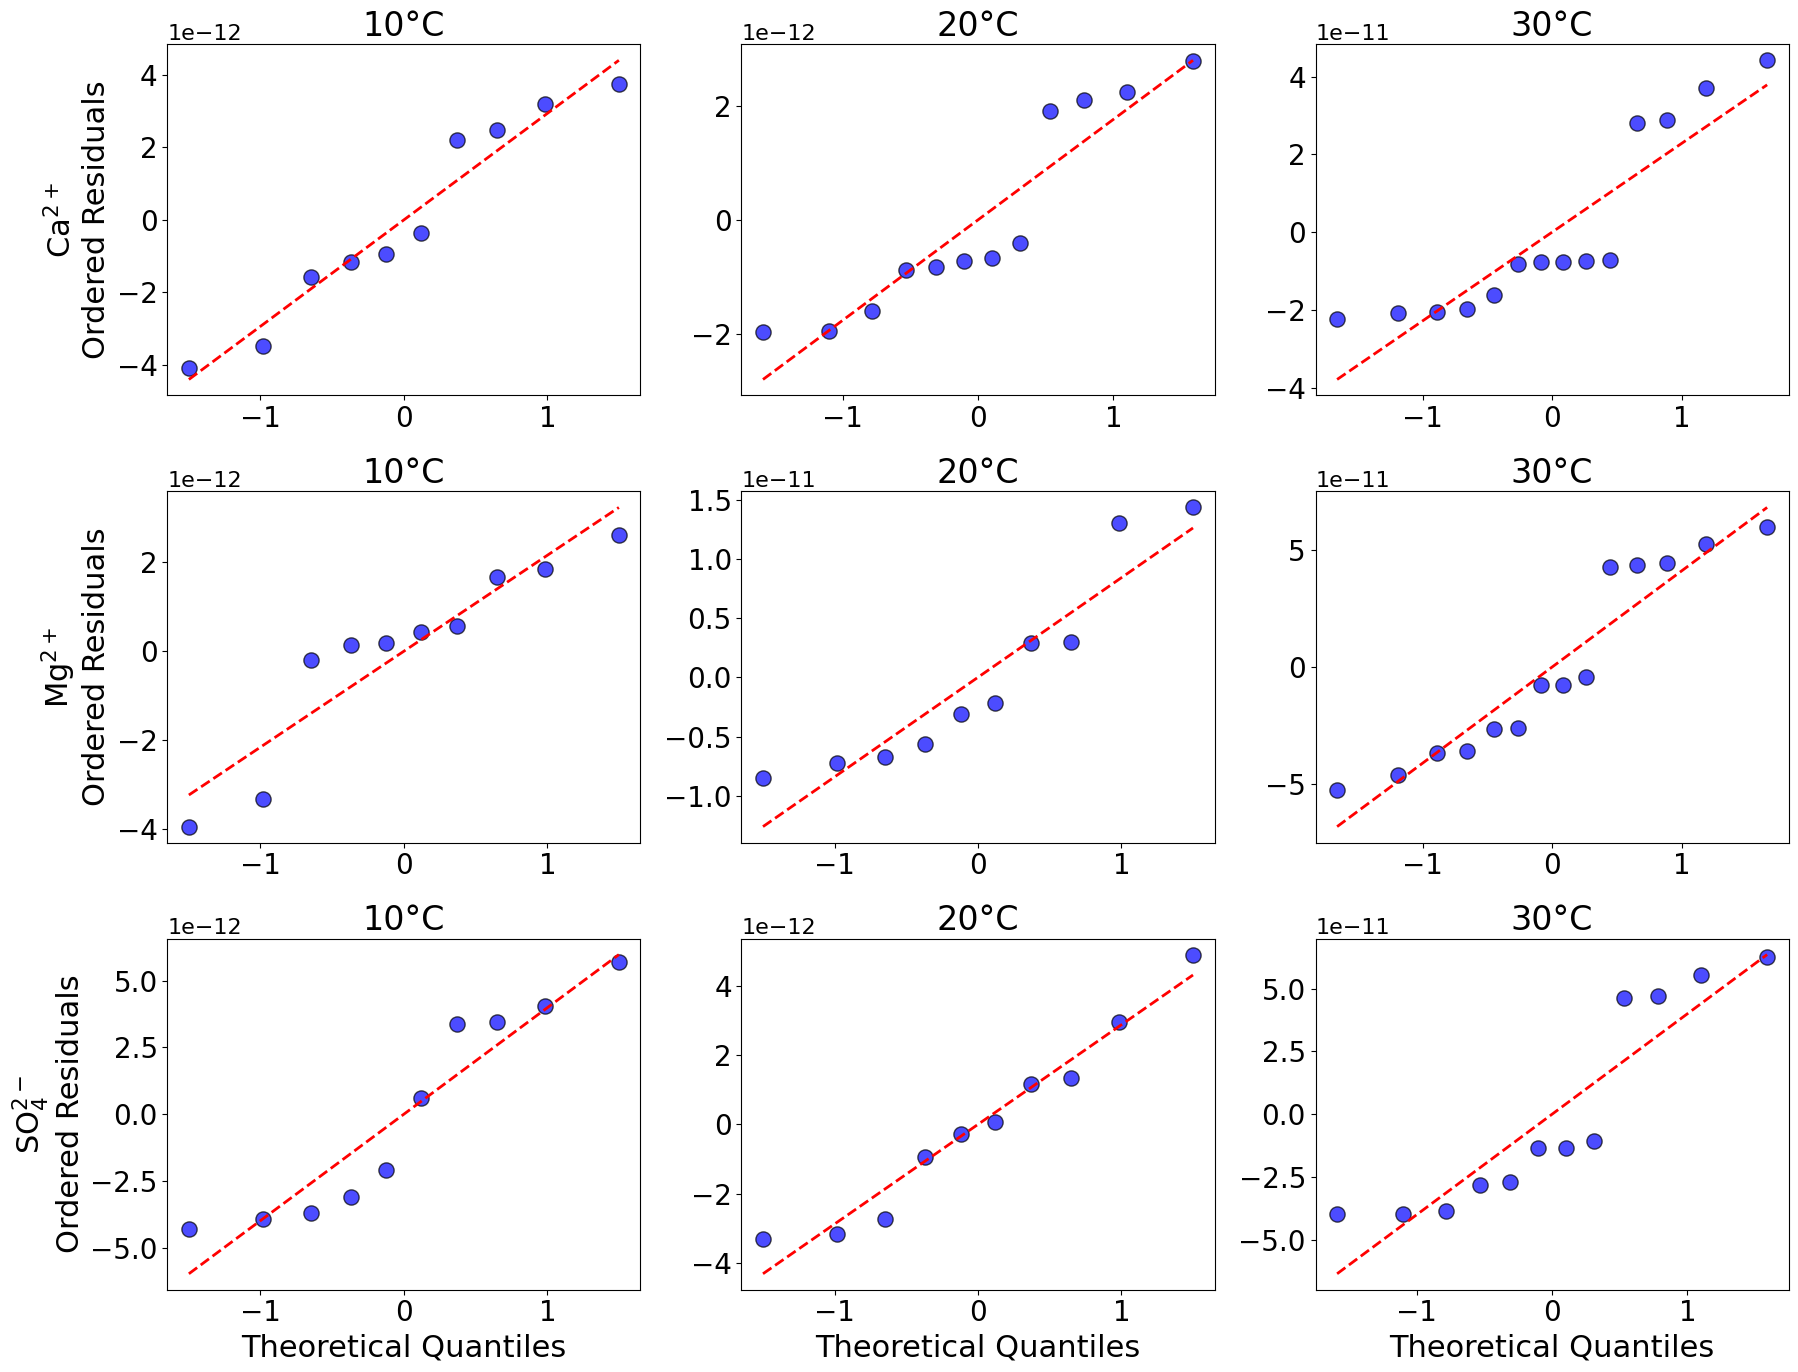

In [53]:
# Appendix Figures A1 and A2
#
# Assess regression residuals using normal probability plots for each
# ion–temperature combination.

temps = sorted(dat['Temperature'].unique())  # ensure ordered 10, 20, 30
pK_column = 'K2'

# --- Create subplot grid: rows = ions, cols = temps ---
fig, axes = plt.subplots(len(ions), len(temps), figsize=(18, 14), sharex=False, sharey=False)

# --- Plot settings ---
title_fontsize = 24
label_fontsize = 22
tick_fontsize = 20
marker_size = 120  # larger points

for i, ion in enumerate(ions):
    for j, temp in enumerate(temps):
        data = dat[(dat['Ion'] == ion) & (dat['Temperature'] == temp)].dropna(subset=[pK_column])
        ax = axes[i, j]

        if len(data) > 1:
            x = data['Conc'].values
            y = data[pK_column].values
            res = linregress(x, y)
            residuals = y - (res.intercept + res.slope * x)

            # Normal probability plot with bigger points
            (osm, osr), (slope, intercept, r) = probplot(residuals, dist="norm")
            ax.scatter(osm, osr, s=marker_size, color='blue', alpha=0.7, edgecolor='k')

            # Draw reference line
            ax.plot(osm, slope*osm + intercept, 'r--', linewidth=2)
        else:
            ax.text(0.5, 0.5, 'Insufficient data', ha='center', va='center', fontsize=label_fontsize)

        # --- Custom titles and labels ---
        ax.set_title(f'{temp}°C', fontsize=title_fontsize)
        if j == 0:
            ax.set_ylabel(f'{ion_labels[ion]}\nOrdered Residuals', fontsize=label_fontsize)
        if i == len(ions) - 1:
            ax.set_xlabel('Theoretical Quantiles', fontsize=label_fontsize)
        ax.tick_params(axis='both', labelsize=tick_fontsize)

plt.tight_layout()
fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_A1_A2.png', dpi=600, bbox_inches='tight')
plt.show()


Ion: Ca, Temp: 30°C
  Slope = -4.789e-03, 95% CI = [-5.296e-03, -4.283e-03]
  Intercept = 8.946e+00, 95% CI = [8.934e+00, 8.959e+00]
  Std error of regression = 8.286e-03
  R² = 9.916e-01

Ion: Ca, Temp: 20°C
  Slope = -4.713e-03, 95% CI = [-5.188e-03, -4.239e-03]
  Intercept = 9.107e+00, 95% CI = [9.095e+00, 9.119e+00]
  Std error of regression = 7.762e-03
  R² = 9.924e-01

Ion: Ca, Temp: 10°C
  Slope = -4.596e-03, 95% CI = [-5.032e-03, -4.160e-03]
  Intercept = 9.284e+00, 95% CI = [9.273e+00, 9.295e+00]
  Std error of regression = 7.132e-03
  R² = 9.932e-01

Ion: Mg, Temp: 30°C
  Slope = -2.741e-03, 95% CI = [-3.569e-03, -1.912e-03]
  Intercept = 9.066e+00, 95% CI = [8.960e+00, 9.173e+00]
  Std error of regression = 6.914e-02
  R² = 9.353e-01

Ion: Mg, Temp: 20°C
  Slope = -2.771e-03, 95% CI = [-3.573e-03, -1.969e-03]
  Intercept = 9.228e+00, 95% CI = [9.125e+00, 9.332e+00]
  Std error of regression = 6.690e-02
  R² = 9.404e-01

Ion: Mg, Temp: 10°C
  Slope = -2.780e-03, 95% CI = [-3.

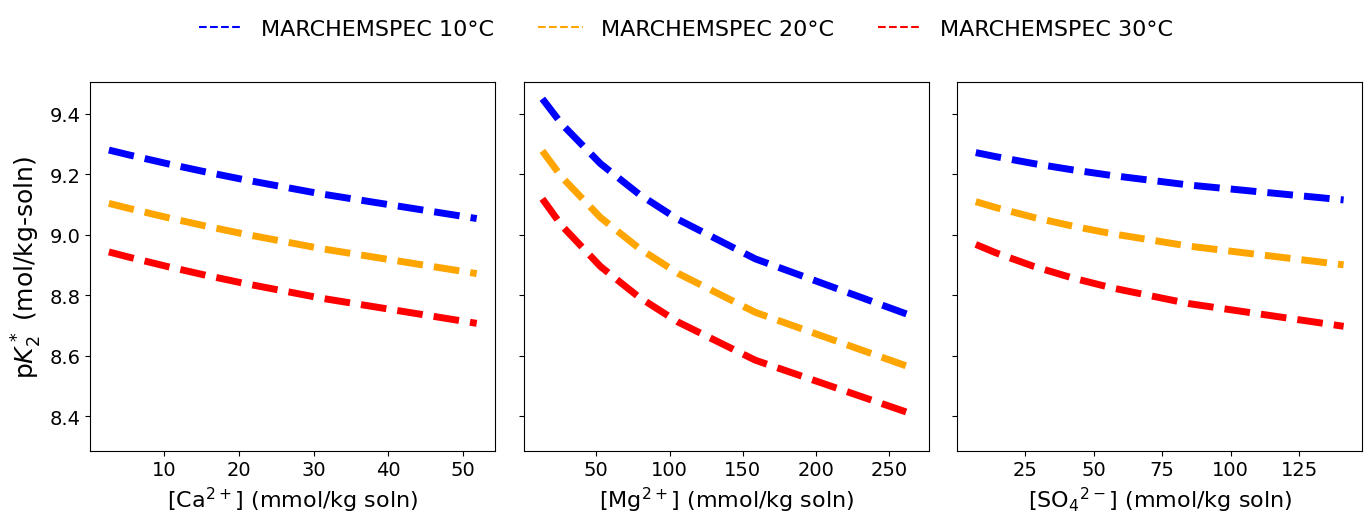

In [54]:
# Appendix Figure D1
#
# Plot pK as a function of ion concentration and report regression
# coefficients with 95% confidence intervals.

pK = 'pK2'

if pK == 'pK1':
    pKlabel = 'p$K_1^*$'
else:
    pKlabel = 'p$K_2^*$'


ions = ['Ca', 'Mg', 'SO4']

# Temperature → color mapping
temp_colors = {
    30: 'red',
    20: 'orange',
    10: 'blue'
}

# === Create 3 horizontal panels ===
fig, axes = plt.subplots(1, 3, figsize=(14, 6), sharey=True)

for ax, ion in zip(axes, ions):
    data_ion = fullrange[fullrange['Ion'] == ion]

    for temp in [30, 20, 10]:
        temp_data = data_ion[data_ion['T_C'] == temp]

        # === Plot data points ===
        ax.plot(
            temp_data['Conc'],
            temp_data[pK],
            marker='',
            markersize=7,
            linestyle='--',
            lw=5,
            color=temp_colors[temp],
            label=f'{temp}°C'
        )

        # === Linear regression ===
        if len(temp_data) < 2:
            continue

        x = temp_data['Conc'].values
        y = temp_data[pK].values
        coeffs = np.polyfit(x, y, 1)  # linear fit
        y_fit = np.polyval(coeffs, x)
        ax.plot(
            x, y_fit,
            linestyle='',
            color=temp_colors[temp],
            linewidth=2
        )

        # Linear regression statistics
        slope, intercept, r_value, p_value, std_err = linregress(x, y)
        n = len(x)
        df = n - 2  # degrees of freedom

        # Standard error of regression
        y_pred = slope*x + intercept
        residuals = y - y_pred
        se_regression = np.sqrt(np.sum(residuals**2) / df)

        # 95% confidence interval for slope and intercept
        tval = stats.t.ppf(0.975, df)
        slope_ci = (slope - tval*std_err, slope + tval*std_err)
        intercept_se = se_regression * np.sqrt(np.sum(x**2)/(n*np.sum((x - np.mean(x))**2)))
        intercept_ci = (intercept - tval*intercept_se, intercept + tval*intercept_se)
        # === Print stats in scientific notation ===
        print(f'Ion: {ion}, Temp: {temp}°C')
        print(f'  Slope = {slope:.3e}, 95% CI = [{slope_ci[0]:.3e}, {slope_ci[1]:.3e}]')
        print(f'  Intercept = {intercept:.3e}, 95% CI = [{intercept_ci[0]:.3e}, {intercept_ci[1]:.3e}]')
        print(f'  Std error of regression = {se_regression:.3e}')
        print(f'  R² = {r_value**2:.3e}\n')


    ax.tick_params(labelsize=14)
    custom_titles = ['[Ca$^{2+}$] (mmol/kg soln)', '[Mg$^{2+}$] (mmol/kg soln)', '[SO$_4$$^{2-}$] (mmol/kg soln)']
    ax.set_xlabel(custom_titles[ions.index(ion)], fontsize=16)

# Shared Y label
axes[0].set_ylabel(f'{pKlabel} (mol/kg-soln)', fontsize=18)

custom_lines = [ # Temperature colors Line2D([0], [0], color='blue', marker='o', linestyle='None', markersize=10, label='10°C'), Line2D([0], [0], color='orange', marker='o', linestyle='None', markersize=10, label='20°C'), Line2D([0], [0], color='red', marker='o', linestyle='None', markersize=10, label='30°C'), # Formulation markers Line2D([0], [0], color='black', marker=' ', linestyle='--', linewidth=3, markersize=10, label='MARCHEMSPEC Regression'), Line2D([0], [0], color='black', marker='s', linestyle='', linewidth=3, markersize=10, label='MARCHEMSPEC Data'), ]
    Line2D([0], [0], color='blue', marker='', linestyle='--', markersize=15, label='MARCHEMSPEC 10°C'),
    Line2D([0], [0], color='orange', marker='', linestyle='--', markersize=15, label='MARCHEMSPEC 20°C'),
    Line2D([0], [0], color='red', marker='', linestyle='--', markersize=15, label='MARCHEMSPEC 30°C'),
    # Formulation markers
    # Line2D([0], [0], color='black', marker=' ', linestyle='--', linewidth=3, markersize=10, label='MARCHEMSPEC Regression'),
    # Line2D([0], [0], color='black', marker='s', linestyle='', linewidth=3, markersize=10, label='MARCHEMSPEC Data'),
]
# === Shared Legend ===
fig.legend(handles=custom_lines, loc='upper center', ncol=6, fontsize=16, frameon=False)

plt.tight_layout(rect=[0, 0.1, 1, 0.9])  # leave space for the legend
fig.savefig(FIGURE_OUTPUT_DIR / 'Figure_D1.png', dpi=600, bbox_inches='tight')
plt.show()
